# Předpověď úspěchu kampaní na Kickstarteru

Semestrální projekt do předmětu 4IZ582. Cílem je předpovědět, zda kampaň na Kickstarteru dosáhne svého finančního cíle, a to pouze z údajů, které jsou o kampani známé v den jejího spuštění.

Pracujeme s kampaněmi spuštěnými v roce 2025. Jde o poslední celý kalendářní rok, takže data pokrývají všechny měsíce a sezónní výkyvy. Rok 2026 v době zpracování ještě neskončil a řada jeho kampaní nemá konečný výsledek. Delší období by naopak výrazně zvětšilo objem dat i časovou náročnost generování LLM příznaků.

Data pocházejí od [Web Robots](https://webrobots.io/kickstarter-datasets/), kteří zveřejňují měsíční snapshoty projektů z Kickstarteru. Pět snapshotů (červen 2025 až březen 2026) jsme spojili v notebooku [`01_data_collection.ipynb`](notebooks/01_data_collection.ipynb), podrobněji v sekci [1.1](#s1-1).

Jako AI část jsme zvolili cestu A, tedy příznaky generované jazykovým modelem. Model na základě názvu a krátkého popisu kampaně vyplní několik jednoduchých příznaků, například jak konkrétní je popis nebo zda jde o pokračování série. Následně porovnáváme klasické modely s těmito příznaky a bez nich.

### Obsah

1. [Analýza dat](#s1): podoba a kvalita dat, zastoupení tříd.
2. [Zajímavé statistiky](#s2): úspěšnost podle hlavních příznaků a vzory nalezené v datech.
3. [Preprocessing](#s3): výběr kampaní, příznaky, rozdělení na trénovací a testovací sadu, závislosti mezi příznaky.
4. [Modely bez LLM příznaků](#s4) (varianta A): referenční model, logistická regrese, gradient boosting, ladění, volba prahu.
5. [LLM příznaky](#s5) (varianty B a C): jejich vznik a přínos.
6. [Vyhodnocení na testovací sadě](#s6) a časová kontrola.
7. [Závěr](#s7).

### Další soubory

- Celý projekt včetně dat je také v repozitáři [github.com/MandelOwO/kickstarter-success-prediction-public](https://github.com/MandelOwO/kickstarter-success-prediction-public).
- [`notebooks/01_data_collection.ipynb`](notebooks/01_data_collection.ipynb): stažení a spojení snapshotů do `_data/prepared/`.
- [`notebooks/02_llm_features.ipynb`](notebooks/02_llm_features.ipynb): generování LLM příznaků. Spouští se samostatně a pouze jednou, výsledky jsou uložené v `_data/ai/llm_features_*.csv`. Tento notebook je pouze načítá, a proto běží offline. Záznam plného běhu je v [`notebooks/02_llm_features.full_run.html`](notebooks/02_llm_features.full_run.html).


### Potřebné balíčky

Notebook jsme spouštěli v Pythonu 3.14, přesné verze balíčků uvádí `requirements.txt`:

```bash
pip install pandas numpy scipy scikit-learn matplotlib jupyter
```

- `pandas`, `numpy`, `jupyter`: práce s daty a spuštění notebooku.
- `scikit-learn`: pipeline, křížová validace, ladění hyperparametrů, modely a metriky.
- `scipy`: rozdělení pro náhodné ladění (`loguniform`, `randint`) a Cramérovo V v sekci [3.9](#s3-9). Instaluje se společně se scikit-learn.
- `matplotlib`: grafy.

Notebook `02_llm_features.ipynb` navíc vyžaduje `pip install openai`, tedy klienta pro školní LiteLLM endpoint s rozhraním kompatibilním s OpenAI. API klíč se načítá z proměnné prostředí nebo ze souboru `.env`.

„Restart Kernel and Run All Cells“ trvá lokálně přibližně 4–6 minut.

### Rozdělení práce

- **Michal Dvořák:** sběr a spojení dat (`01_data_collection.ipynb`), analýza dat a preprocessing.
- **Hana Veselá:** AI část (`02_llm_features.ipynb`), modely.
- **Společně:** výběr datasetu a cílové proměnné, rozdělení dat podle tvůrců, ruční dotazník pro jazykový model, vyhodnocení a interpretace výsledků.

### Použití AI nástrojů

Při práci jsme používali AI asistenta Claude (Claude Code, Anthropic). Využívali jsme jej k:
- psaní a úpravám kódu na základě stanovených požadavků a rozhodnutí
- konzultaci postupu: výběr modelů a metrik, volba prahu, plán srovnání variant A, B a C
- kontrole: hledání možných úniků informace, kontrola notebooku proti zadání a reprodukovatelnosti
- formulaci a jazykové revizi textových buněk

Zásadní rozhodnutí jsme dělali sami: výběr datasetu a roku 2025, cílovou proměnnou, rozdělení dat podle tvůrců, ruční dotazník pro jazykový model a úpravu dotazníku navrženého modelem. Výstupy asistenta jsme průběžně kontrolovali: notebook jsme opakovaně spouštěli, čísla v textu porovnávali s výstupy buněk a řadu návrhů jsme upravili nebo odmítli.

<a id="s1"></a>
## 1. Analýza dat

<a id="s1-1"></a>
### 1.1 Zdroj a načtení

Jeden řádek odpovídá jednomu projektu spuštěnému v roce 2025 (čas UTC). Data pocházejí od [Web Robots](https://webrobots.io/kickstarter-datasets/), kteří přibližně jednou měsíčně stahují údaje o projektech na Kickstarteru. Jednotlivé snapshoty jsou téměř úplné, vždy v nich však část projektů chybí. Například samotný nejnovější snapshot z března 2026 neobsahuje 3 627 projektů spuštěných v roce 2025, které se vyskytují v některém ze starších snapshotů.

Proto jsme nepoužili pouze nejnovější snapshot, ale spojili jsme pět snapshotů (červen 2025 až březen 2026). Pro každý projekt ponecháváme řádek z nejnovějšího snapshotu, v němž se vyskytuje, protože ten s největší pravděpodobností zachycuje konečný stav kampaně. Postup je popsán v notebooku [`01_data_collection.ipynb`](notebooks/01_data_collection.ipynb). Výsledek je kvůli velikosti uložen po částech v `_data/prepared/kickstarter_projects_2025_part_*.csv`. Balíček odevzdaný v InSIS tyto soubory kvůli limitu velikosti neobsahuje. Pokud ve složce chybí, následující buňka je stáhne z [repozitáře projektu](https://github.com/MandelOwO/kickstarter-success-prediction-public) (přibližně 190 MB).

In [1]:
import json
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

DATA_URL = "https://raw.githubusercontent.com/MandelOwO/kickstarter-success-prediction-public/refs/heads/main/_data/prepared/"
part_names = [f"kickstarter_projects_2025_part_{i:03d}.csv" for i in range(1, 5)]

prepared_dir = Path("_data/prepared")
if not prepared_dir.is_dir() and Path("../_data/prepared").is_dir():
    prepared_dir = Path("../_data/prepared")

# Chybějící části stáhneme z GitHubu. Soubor se přejmenuje až po úplném stažení.
prepared_dir.mkdir(parents=True, exist_ok=True)
for name in part_names:
    path = prepared_dir / name
    if not path.exists():
        print(f"Stahuji {name}…")
        urlretrieve(DATA_URL + name, path.with_suffix(".tmp"))
        path.with_suffix(".tmp").rename(path)

part_paths = [prepared_dir / name for name in part_names]


raw_projects = pd.concat(
    [pd.read_csv(path, dtype=str, keep_default_na=False) for path in part_paths],
    ignore_index=True,
)
print(f"Načteno {len(part_paths)} částí, {len(raw_projects):,} projektů a {raw_projects.shape[1]} sloupců.")

Načteno 4 částí, 29,599 projektů a 48 sloupců.


<a id="s1-2"></a>
### 1.2 Rozměry, ukázka řádků a sloupce

První tabulka uvádí základní údaje pěti kampaní, druhá všechny sloupce prvních tří kampaní v transponované podobě. Data načítáme jako text a typy převádíme až v následujícím kroku.

In [2]:
preview_columns = ["id", "name", "state", "country", "currency", "goal", "launched_at"]
display(raw_projects[preview_columns].head())

print("3 záznamy, transformovaná tabulka:")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 80):
    display(raw_projects.head(3).T)

,id,name,state,country,currency,goal,launched_at
0,19795,Lost Mine - Dice Tower - 3D Printable STL Files,successful,US,USD,100,1763350611
1,118563,Capture Life's Moments in 8K: DualView2 Dual-S...,successful,HK,HKD,30000,1741870791
2,164004,Dark Elf Buildings - Painted Terrain for Table...,successful,US,USD,15000,1760536814
3,283033,Square RPG Puzzle Tiles - FANTASY INTERIORS,successful,US,USD,1000,1760782994
4,298151,Dragons: Wild and Domestic,successful,US,USD,9000,1754067771


3 záznamy, transformovaná tabulka:


,0,1,2
backers_count,96,65,14
blurb,"3D Printable Pieces for Wargames, Tabletop RPGs & Boardgames, Medieval, Fantasy",8K | Dual Screens | 90g Ultra-light | 6-Axis Horizon Stabilization | Touchsc...,"Painted Terrain, officially licensed from EC3D Designs, ready to play, no pr..."
category,"{""id"":34,""name"":""Tabletop Games"",""analytics_name"":""Tabletop Games"",""slug"":""g...","{""id"":52,""name"":""Hardware"",""analytics_name"":""Hardware"",""slug"":""technology/ha...","{""id"":34,""name"":""Tabletop Games"",""analytics_name"":""Tabletop Games"",""slug"":""g..."
converted_pledged_amount,1035,19193,16853
country,US,HK,US
country_displayable_name,the United States,Hong Kong,the United States
created_at,1763271298,1735107428,1757434039
creator,"{""id"":597395734,""name"":""New Leaf 3D"",""slug"":""newleaf3d"",""is_registered"":null...","{""id"":1489434413,""name"":""DualView"",""slug"":""dualview"",""is_registered"":null,""i...","{""id"":431443045,""name"":""Richard Parla"",""slug"":""lrterrain"",""is_registered"":nu..."
currency,USD,HKD,USD
currency_symbol,$,$,$


<a id="s1-3"></a>
### 1.3 Čištění a kontrola kvality

Pro průzkum vytvoříme kopii dat a převedeme potřebné údaje: časy z Unix sekund na datum v UTC, z JSONu kategorie získáme hlavní kategorii a podkategorii (u projektů zařazených přímo do hlavní kategorie je podkategorie shodná) a prázdné texty považujeme za chybějící hodnoty. Následně provedeme několik kontrol kvality.

In [3]:
projects = raw_projects.copy()


def parse_category(raw_value):
    try:
        category = json.loads(raw_value)
    except json.JSONDecodeError:
        return None, None
    if not isinstance(category, dict):
        return None, None
    name = category.get("name")
    return category.get("parent_name") or name, name


for column in ("launched_at", "deadline", "created_at", "state_changed_at"):
    seconds = pd.to_numeric(projects[column], errors="coerce")
    projects[column] = pd.to_datetime(seconds.where(seconds.gt(0)), unit="s", utc=True, errors="coerce")

for column in ("id", "country", "currency", "name", "blurb"):
    projects[column] = projects[column].str.strip().replace("", pd.NA)

projects["snapshot_last_seen"] = pd.to_datetime(
    projects["snapshot_last_seen"], format="%Y-%m-%d", utc=True, errors="coerce"
)
conflict_flags = projects["snapshot_has_state_or_launch_conflict"].str.strip().str.lower()
assert conflict_flags.isin(["true", "false"]).all(), "Neznámá hodnota příznaku konfliktu."
projects["snapshot_conflict"] = conflict_flags.eq("true")
projects["goal"] = pd.to_numeric(projects["goal"], errors="coerce")
projects[["main_category", "subcategory"]] = pd.DataFrame(
    projects["category"].map(parse_category).tolist(), index=projects.index
)
projects["duration_days"] = (projects["deadline"] - projects["launched_at"]).dt.total_seconds() / 86_400
projects["launch_month"] = projects["launched_at"].dt.strftime("%Y-%m")

assert projects["id"].notna().all() and projects["id"].is_unique, "Očekáváme právě jeden řádek na ID."
assert projects["launched_at"].dt.year.eq(2025).all(), "Očekáváme spuštění v roce 2025."

projects["success"] = projects["state"].map({"successful": 1, "failed": 0}).astype("Int8")
finished = projects.loc[projects["success"].notna()].copy()

quality_checks = pd.Series({
    "Duplicitní ID": projects["id"].duplicated().sum(),
    "Chybějící nebo nečitelná kategorie": projects["main_category"].isna().sum(),
    "Chybějící země": projects["country"].isna().sum(),
    "Chybějící měna": projects["currency"].isna().sum(),
    "Chybějící název": projects["name"].isna().sum(),
    "Chybějící popis": projects["blurb"].isna().sum(),
    "Chybějící či nekladný cíl¹": (~(np.isfinite(finished["goal"]) & finished["goal"].gt(0))).sum(),
    "Chybějící či nekladná délka¹": (~finished["duration_days"].gt(0)).sum(),
    "Délka alespoň 61 dní¹": finished["duration_days"].ge(61).sum(),
    "Konflikt stavu nebo spuštění¹": finished["snapshot_conflict"].sum(),
    "Výsledek po dni posledního snapshotu¹": (
        finished["state_changed_at"].dt.normalize().gt(finished["snapshot_last_seen"])
    ).sum(),
}, name="Počet")
display(quality_checks.to_frame())

,Počet
Duplicitní ID,0
Chybějící nebo nečitelná kategorie,0
Chybějící země,0
Chybějící měna,0
Chybějící název,0
Chybějící popis,1
Chybějící či nekladný cíl¹,0
Chybějící či nekladná délka¹,0
Délka alespoň 61 dní¹,8
Konflikt stavu nebo spuštění¹,7


¹ Počítáno pouze mezi projekty se známým výsledkem. Ostatní kontroly zahrnují všech 29 599 řádků.

Data jsou poměrně čistá, chybí pouze jeden popis. Problematické jsou dvě malé skupiny. U 7 projektů se snapshoty rozcházejí ve stavu nebo v datu spuštění a 8 dokončených kampaní trvá podle uložených časů 61 a více dní (nejdelší 100,7 dne), přestože Kickstarter povoluje nejvýše 60 dní. Obě skupiny z modelování vyřazujeme ([3.1](#s3-1)). Menší překročení 60 dní ponecháváme, protože jde pravděpodobně pouze o nepřesnost v uložených časech.

In [4]:
projects.head(5)

,backers_count,blurb,category,converted_pledged_amount,country,country_displayable_name,created_at,creator,currency,currency_symbol,...,snapshot_count,snapshot_dates,snapshot_source_file,snapshot_has_state_or_launch_conflict,snapshot_conflict,main_category,subcategory,duration_days,launch_month,success
0,96,"3D Printable Pieces for Wargames, Tabletop RPG...","{""id"":34,""name"":""Tabletop Games"",""analytics_na...",1035,US,the United States,2025-11-16 05:34:58+00:00,"{""id"":597395734,""name"":""New Leaf 3D"",""slug"":""n...",USD,$,...,3,2025-12-18|2026-01-12|2026-03-12,Kickstarter038.csv,False,False,Games,Tabletop Games,7.000000,2025-11,1
1,65,8K | Dual Screens | 90g Ultra-light | 6-Axis H...,"{""id"":52,""name"":""Hardware"",""analytics_name"":""H...",19193,HK,Hong Kong,2024-12-25 06:17:08+00:00,"{""id"":1489434413,""name"":""DualView"",""slug"":""dua...",HKD,$,...,5,2025-06-12|2025-07-14|2025-12-18|2026-01-12|20...,Kickstarter002.csv,False,False,Technology,Hardware,30.000000,2025-03,1
2,14,"Painted Terrain, officially licensed from EC3D...","{""id"":34,""name"":""Tabletop Games"",""analytics_na...",16853,US,the United States,2025-09-09 16:07:19+00:00,"{""id"":431443045,""name"":""Richard Parla"",""slug"":...",USD,$,...,3,2025-12-18|2026-01-12|2026-03-12,Kickstarter036.csv,False,False,Games,Tabletop Games,30.000000,2025-10,1
3,41,"Complete sets of RPG tiles, optimized for quic...","{""id"":34,""name"":""Tabletop Games"",""analytics_na...",1775,US,the United States,2025-10-17 17:47:32+00:00,"{""id"":1769996199,""name"":""Hermann Hillmann"",""sl...",USD,$,...,3,2025-12-18|2026-01-12|2026-03-12,Kickstarter067.csv,False,False,Games,Tabletop Games,15.041667,2025-10,1
4,335,An art book by Jaimie Whitbread,"{""id"":45,""name"":""Art Books"",""analytics_name"":""...",19769,US,the United States,2025-04-16 21:19:19+00:00,"{""id"":625829517,""name"":""Jaimie"",""slug"":""jaimie...",USD,$,...,3,2025-12-18|2026-01-12|2026-03-12,Kickstarter004.csv,False,False,Publishing,Art Books,30.000000,2025-08,1


<a id="s1-4"></a>
### 1.4 Zastoupení stavů

Tabulka zahrnuje všechny zachycené projekty včetně těch, které v době sběru ještě probíhaly.

In [5]:
state_counts = projects["state"].value_counts().rename("Počet projektů")
display(state_counts.to_frame().assign(Podíl=state_counts.div(len(projects)).map("{:.1%}".format)))

,Počet projektů,Podíl
state,,
successful,18836,63.6%
failed,7806,26.4%
live,1770,6.0%
canceled,1187,4.0%


Stav odpovídá poslednímu snapshotu, ve kterém se projekt vyskytuje. Následující kontrola ukazuje, ze kterých snapshotů pocházejí projekty ve stavu `live`.

In [6]:
last_snapshot = projects["snapshot_last_seen"].dt.strftime("%Y-%m-%d")
live_by_snapshot = last_snapshot[projects["state"].eq("live")].value_counts().sort_index()
display(live_by_snapshot.rename("Projektů ve stavu live").to_frame())

finished_last_snapshot = finished["snapshot_last_seen"].dt.strftime("%Y-%m-%d")
from_older_snapshot = finished_last_snapshot.ne(last_snapshot.max())
print(
    f"Dokončené kampaně naposledy zachycené ve starším snapshotu: {from_older_snapshot.sum():,}, "
    f"úspěšnost {finished.loc[from_older_snapshot, 'success'].astype(float).mean():.1%} "
    f"(všechny dokončené kampaně {finished['success'].astype(float).mean():.1%})"
)

,Projektů ve stavu live
snapshot_last_seen,
2025-06-12,556
2025-07-14,624
2025-12-18,352
2026-01-12,238


Dokončené kampaně naposledy zachycené ve starším snapshotu: 1,755, úspěšnost 81.9% (všechny dokončené kampaně 70.7%)


Žádný projekt ve stavu `live` nepochází z nejnovějšího snapshotu (březen 2026). Jde o projekty, které v době některého staršího snapshotu ještě probíhaly a v pozdějších snapshotech již chybí, jejich konečný výsledek proto neznáme. Úbytek přitom není náhodný: dokončené kampaně, které jsou naposledy zachycené ve starším snapshotu, uspívají v 82 % případů oproti 71 % celkově. Projekty, které z pozdějších snapshotů zmizely, tedy mohly mít jinou úspěšnost než ostatní.

Model trénujeme pouze na dokončených kampaních, tedy `successful` (1) a `failed` (0). U projektů ve stavu `live` konečný výsledek neznáme a kampaně `canceled` ukončil sám tvůrce před termínem.

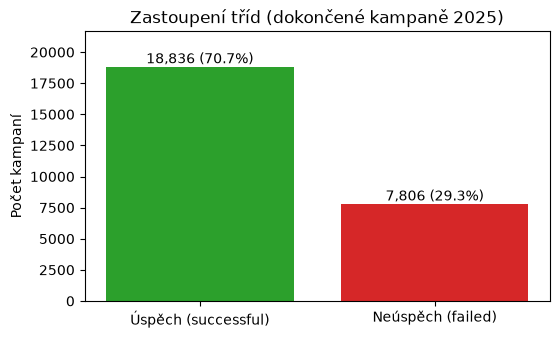

In [7]:
target_counts = finished["state"].value_counts().reindex(["successful", "failed"])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Úspěch (successful)", "Neúspěch (failed)"], target_counts, color=["tab:green", "tab:red"])
for position, count in enumerate(target_counts):
    ax.text(position, count, f"{count:,} ({count / target_counts.sum():.1%})", ha="center", va="bottom")
ax.set_ylabel("Počet kampaní")
ax.set_title("Zastoupení tříd (dokončené kampaně 2025)")
ax.set_ylim(0, target_counts.max() * 1.15)
plt.show()

Úspěšných kampaní je přibližně 70 %, nevyváženost tříd je tedy mírná. Její důsledky pro volbu metriky a prahu popisuje [sekce 4](#s4).

<a id="s2"></a>
## 2. Zajímavé statistiky

Úspěšnost vždy počítáme jako podíl kampaní `successful` mezi kampaněmi ve stavu `successful` nebo `failed`. Celkově uspělo 70,7 % z 26 642 dokončených kampaní. Průzkum zahrnuje celý rok včetně kampaní, které později připadnou do testovací sady, důsledky popisuje [3.5](#s3-5).

<a id="s2-1"></a>
### 2.1 Výsledky podle měsíce spuštění

Tabulka uvádí všechny stavy, aby bylo zřejmé, jaká část kampaní z každého měsíce má známý výsledek.

In [8]:
monthly = pd.crosstab(projects["launch_month"], projects["state"])
monthly["Se známým výsledkem"] = monthly["successful"] + monthly["failed"]
monthly["Úspěšnost"] = monthly["successful"].div(monthly["Se známým výsledkem"])
monthly["Známý výsledek z celku"] = monthly["Se známým výsledkem"].div(
    projects.groupby("launch_month").size()
)
monthly_display = monthly.copy()
for column in ("Úspěšnost", "Známý výsledek z celku"):
    monthly_display[column] = monthly[column].map("{:.1%}".format)
display(monthly_display)

state,canceled,failed,live,successful,Se známým výsledkem,Úspěšnost,Známý výsledek z celku
launch_month,,,,,,,
2025-01,92,666,0,1404,2070,67.8%,95.7%
2025-02,73,630,0,1581,2211,71.5%,96.8%
2025-03,113,617,0,1638,2255,72.6%,95.2%
2025-04,94,650,62,1596,2246,71.1%,93.5%
2025-05,128,699,349,1587,2286,69.4%,82.7%
2025-06,129,717,510,1641,2358,69.6%,78.7%
2025-07,96,686,259,1550,2236,69.3%,86.3%
2025-08,89,587,0,1472,2059,71.5%,95.9%
2025-09,77,670,0,1790,2460,72.8%,97.0%


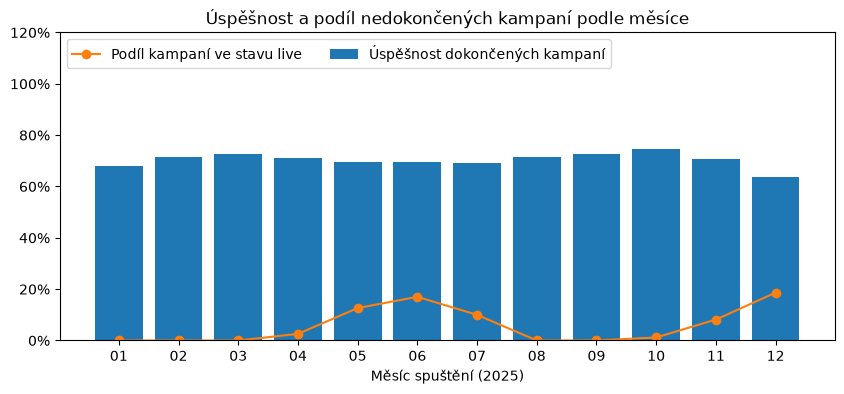

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
months = monthly.index.str[5:]
ax.bar(months, monthly["Úspěšnost"], color="tab:blue", label="Úspěšnost dokončených kampaní")
live_share = monthly["live"].div(projects.groupby("launch_month").size())
ax.plot(months, live_share, color="tab:orange", marker="o", label="Podíl kampaní ve stavu live")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, 1.2)
ax.set_xlabel("Měsíc spuštění (2025)")
ax.set_title("Úspěšnost a podíl nedokončených kampaní podle měsíce")
ax.legend(loc="upper left", ncol=2)
plt.show()

Úspěšnost je v průběhu roku poměrně stabilní, většinou mezi 68 a 75 %. Nejvyšší je v říjnu (74,5 % z 2 800 kampaní), nejnižší v prosinci (63,9 % z 1 442). V červnu a v prosinci je však více než 17 % kampaní ve stavu `live`, tedy projektů, které z pozdějších snapshotů zmizely ([1.4](#s1-4)). Tyto kampaně do výpočtu nevstupují, a dokončené kampaně z těchto měsíců proto nemusí být reprezentativní. Skutečnou sezónnost od tohoto vlivu proto z dostupných dat neodlišíme.

<a id="s2-2"></a>
### 2.2 Hlavní kategorie

U každého sloupce je uvedena úspěšnost a počet dokončených kampaní, přerušovaná čára označuje průměr za všechny kampaně. Stejný typ grafu používáme v celé sekci.

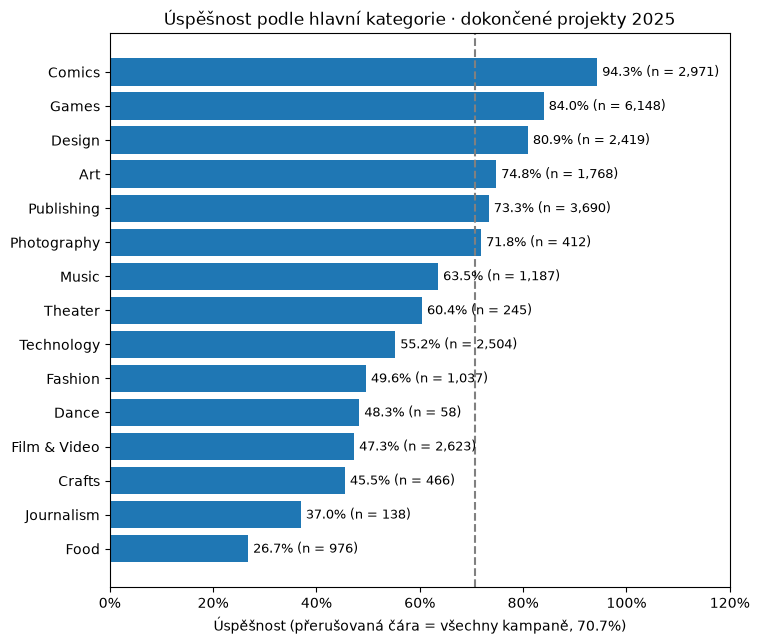

In [10]:
overall_rate = finished["success"].mean()


def show_success_chart(summary, title):
    """Vodorovný sloupcový graf úspěšnosti. Summary má sloupce n (počet) a rate (úspěšnost)."""
    labels = [str(label) for label in summary.index]
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(summary) + 1.2))
    ax.barh(labels, summary["rate"], color="tab:blue")
    ax.axvline(overall_rate, color="grey", linestyle="--")
    for position, (rate, count) in enumerate(zip(summary["rate"], summary["n"])):
        ax.text(rate + 0.01, position, f"{rate:.1%} (n = {count:,})", va="center", fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.2)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel(f"Úspěšnost (přerušovaná čára = všechny kampaně, {overall_rate:.1%})")
    ax.set_title(title)
    plt.show()


category_summary = finished.groupby("main_category", dropna=False)["success"].agg(n="size", rate="mean")
show_success_chart(category_summary.sort_values("rate", ascending=False),
                   "Úspěšnost podle hlavní kategorie · dokončené projekty 2025")

Rozdíly mezi kategoriemi jsou výrazné. Comics dosahují úspěšnosti 94,3 %, Games 84,0 % (s 6 148 kampaněmi jde o nejpočetnější kategorii), Food pouze 26,7 %.

Domníváme se, že rozdíl souvisí především s tím, co podporovatel za svůj příspěvek získá. U komiksů a her jde obvykle o konkrétní produkt, a podporovatel si jej fakticky kupuje předem. Kampaně v kategoriích Food nebo Journalism častěji financují provoz podniku, službu nebo veřejně prospěšný záměr, za který podporovatel hmatatelnou odměnu nedostává. Jde o naši hypotézu, kterou jsme přímo neověřovali. Nepřímo ji podporují LLM příznaky v sekci [5.3](#s5-3): kampaně bez hmatatelné odměny uspívají ve 40 % případů (s odměnou v 77 %) a kampaně financující provoz podniku ve 20 %.

Kategorie bude součástí modelu. Podkategorií je výrazně více a některé obsahují jen několik kampaní, s čímž musí počítat kódování: hodnota, kterou model při trénování neviděl, nesmí způsobit chybu.

<a id="s2-3"></a>
### 2.3 Finanční cíl

Cíle zde porovnáváme pouze u kampaní vedených v USD, abychom nesrovnávali částky v různých měnách. Pro model cíl převádíme do USD (viz [3.2](#s3-2)).

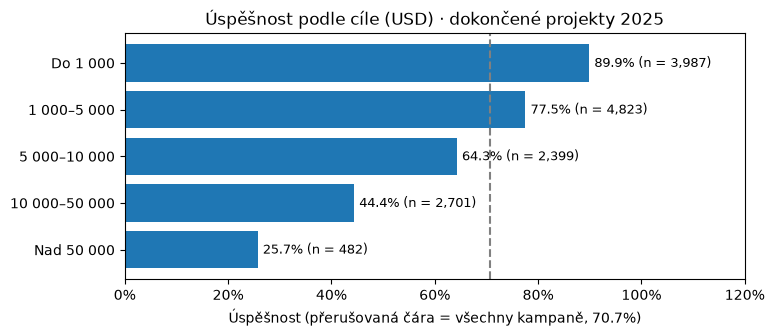

,Cíl v USD
Medián,4000
90. percentil,26180
99. percentil,106071


In [11]:
goal_bands = ["Do 1 000", "1 000–5 000", "5 000–10 000", "10 000–50 000", "Nad 50 000"]
usd_projects = finished.loc[
    finished["currency"].eq("USD") & np.isfinite(finished["goal"]) & finished["goal"].gt(0)
].copy()
usd_projects["goal_band"] = pd.cut(
    usd_projects["goal"], [0, 1_000, 5_000, 10_000, 50_000, np.inf], labels=goal_bands
)
goal_summary = usd_projects.groupby("goal_band", observed=False)["success"].agg(n="size", rate="mean")
show_success_chart(goal_summary, "Úspěšnost podle cíle (USD) · dokončené projekty 2025")
goal_quantiles = usd_projects["goal"].quantile([0.5, 0.9, 0.99]).round().astype(int)
display(goal_quantiles.set_axis(["Medián", "90. percentil", "99. percentil"]).to_frame("Cíl v USD"))

S rostoucím cílem úspěšnost výrazně klesá, z 90 % u cílů do 1 000 USD na 26 % u cílů nad 50 000 USD. Rozdělení cílů je výrazně nesymetrické: medián je 4 000 USD, avšak 1 % kampaní požaduje více než 106 000 USD. Cíl proto v modelu logaritmujeme (`log1p`) namísto ořezávání extrémních hodnot. Velmi vysoké cíle ponecháváme, protože data neumožňují rozhodnout, zda jsou chybné. Pásma v grafu zahrnují svou horní hranici, model však pracuje se spojitou hodnotou.

<a id="s2-4"></a>
### 2.4 Finanční cíl uvnitř kategorií

Vysoký cíl i obtížnější kategorie snižují pravděpodobnost úspěchu. Zajímalo nás, zda má cíl ve všech kategoriích stejný vliv. Mapa zobrazuje úspěšnost pro každou kombinaci kategorie a pásma cíle (pouze kampaně v USD). Políčka s méně než 20 kampaněmi ponecháváme prázdná.

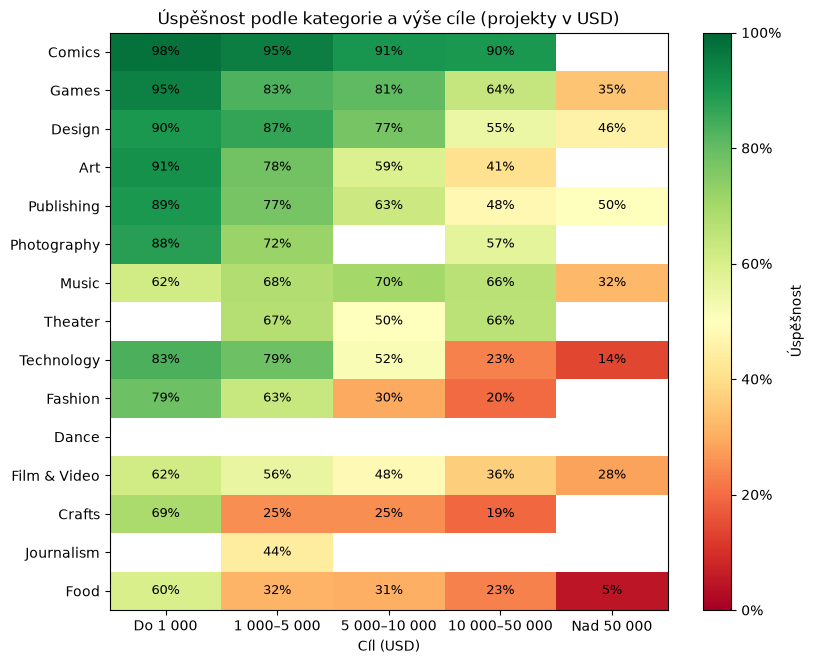

In [12]:
min_projects = 20
category_order = category_summary.sort_values("rate", ascending=False).index

goal_rates = usd_projects.pivot_table(
    index="main_category", columns="goal_band", values="success", aggfunc="mean", observed=False
).reindex(category_order)
goal_counts = usd_projects.pivot_table(
    index="main_category", columns="goal_band", values="success", aggfunc="size", observed=False
).reindex(category_order).fillna(0)
goal_rates = goal_rates.where(goal_counts >= min_projects)

fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(goal_rates.astype(float), cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
for row in range(goal_rates.shape[0]):
    for column in range(goal_rates.shape[1]):
        rate = goal_rates.iloc[row, column]
        if pd.notna(rate):
            ax.text(column, row, f"{rate:.0%}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(len(goal_bands)), goal_bands)
ax.set_yticks(range(len(category_order)), category_order)
ax.set_xlabel("Cíl (USD)")
ax.set_title("Úspěšnost podle kategorie a výše cíle (projekty v USD)")
fig.colorbar(image, ax=ax, label="Úspěšnost", format=PercentFormatter(1))
plt.show()

Úspěšnost s rostoucím cílem klesá ve všech kategoriích, avšak různě rychle. Comics si udržují 90 % i u cílů 10 000–50 000 USD, zatímco Games klesají z 95 % na 64 % a Food z 60 % na 23 %. Vliv cíle tedy závisí na kategorii. 

<a id="s2-5"></a>
### 2.5 Délka kampaně

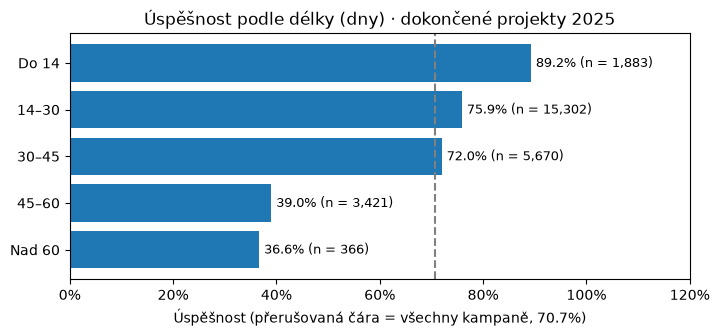

In [13]:
duration_bands = ["Do 14", "14–30", "30–45", "45–60", "Nad 60"]
duration_group = pd.cut(
    finished["duration_days"], [0, 14, 30, 45, 60, np.inf], labels=duration_bands
)
duration_summary = finished.groupby(duration_group, observed=False)["success"].agg(n="size", rate="mean")
show_success_chart(duration_summary, "Úspěšnost podle délky (dny) · dokončené projekty 2025")

Kratší kampaně uspívají častěji: kampaně do 14 dní v 89 % případů, kampaně trvající 45–60 dní pouze ve 39 %. Většina kampaní trvá 14–30 dní, medián je 30 dní. Rozdíl může částečně souviset s výší cíle, protože kratší kampaně mívají nižší cíle. Délku počítáme z uloženého termínu ukončení, předpokládáme tedy, že se po spuštění neměnil.

<a id="s2-6"></a>
### 2.6 Kolik kampaně skutečně vybraly

Kickstarter funguje na principu „vše, nebo nic“: tvůrce obdrží peníze pouze tehdy, pokud kampaň dosáhne cíle. Graf ukazuje, jakou část cíle kampaně skutečně vybraly. Kampaně nad 300 % cíle by graf výrazně roztáhly, proto uvádíme pouze jejich počet. Vybraná částka je výsledkem kampaně, do modelu proto nevstupuje.

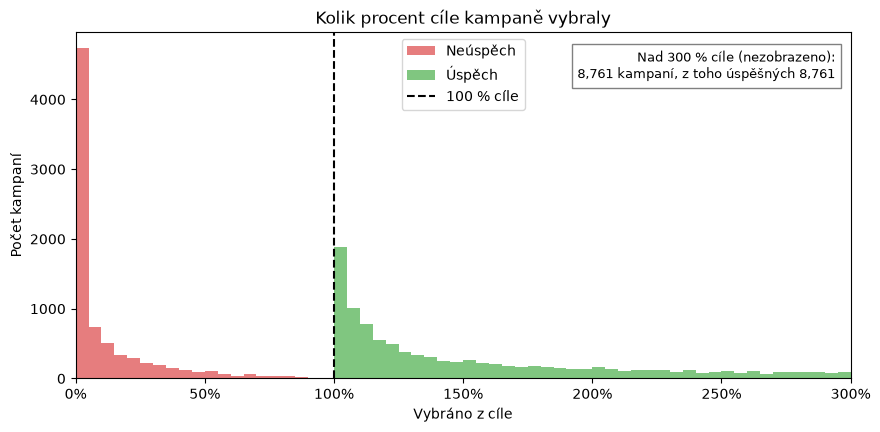

Neúspěšné kampaně, které vybraly nejvýše 5 % cíle: 60.9%
Neúspěšné kampaně, které vybraly 50–80 % cíle: 346
Neúspěšné kampaně, které vybraly 80–100 % cíle: 65
Úspěšné kampaně, které vybraly více než dvojnásobek cíle: 57.2%
Úspěšné kampaně, které vybraly více než trojnásobek cíle: 46.5%


In [14]:
funded_ratio = pd.to_numeric(finished["pledged"], errors="coerce") / finished["goal"]
max_ratio = 3  # osa do 300 % cíle
ratio_bins = np.arange(0, max_ratio + 0.05, 0.05)  # sloupce po 5 procentních bodech
above_max = funded_ratio.gt(max_ratio)

fig, ax = plt.subplots(figsize=(10, 4.5))
for state, label, color in [("failed", "Neúspěch", "tab:red"), ("successful", "Úspěch", "tab:green")]:
    ratios = funded_ratio[finished["state"].eq(state) & ~above_max]
    ax.hist(ratios, bins=ratio_bins, color=color, alpha=0.6, label=label)
ax.axvline(1, color="black", linestyle="--", label="100 % cíle")
above_successful = (above_max & finished["state"].eq("successful")).sum()
ax.text(0.98, 0.95, f"Nad 300 % cíle (nezobrazeno):\n{above_max.sum():,} kampaní, z toho úspěšných {above_successful:,}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "grey"})
ax.set_xlim(0, max_ratio)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Vybráno z cíle")
ax.set_ylabel("Počet kampaní")
ax.set_title("Kolik procent cíle kampaně vybraly")
ax.legend(loc="upper center")
plt.show()

failed_ratio = funded_ratio[finished["state"].eq("failed")]
successful_ratio = funded_ratio[finished["state"].eq("successful")]
print(f"Neúspěšné kampaně, které vybraly nejvýše 5 % cíle: {failed_ratio.le(0.05).mean():.1%}")
print(f"Neúspěšné kampaně, které vybraly 50–80 % cíle: {failed_ratio.between(0.5, 0.8).sum():,}")
print(f"Neúspěšné kampaně, které vybraly 80–100 % cíle: {failed_ratio.between(0.8, 1).sum():,}")
print(f"Úspěšné kampaně, které vybraly více než dvojnásobek cíle: {successful_ratio.gt(2).mean():.1%}")
print(f"Úspěšné kampaně, které vybraly více než trojnásobek cíle: {successful_ratio.gt(3).mean():.1%}")

Rozdělení je výrazně dvouvrcholové. Neúspěšné kampaně většinou nevyberou téměř nic: 61 % z nich skončí do 5 % cíle a těsně pod cílem (80–100 %) skončilo pouze 65 kampaní. Úspěšné kampaně naopak cíl často několikanásobně překročí, 57 % z nich vybere více než dvojnásobek a 46 % dokonce více než trojnásobek cíle. Kampaně tedy jen zřídka skončí těsně pod cílem: buď získají dostatečnou podporu, nebo téměř žádnou. Pro predikci je to příznivé zjištění, protože se obě třídy výrazně liší.

Několik úspěšných kampaní má poměr nižší než 100 %. Důvod z dat neznáme, může jít například o příspěvky zrušené po skončení kampaně.

<a id="s2-7"></a>
### 2.7 Příprava kampaně: prelaunch, video a doba přípravy

Sledujeme tři charakteristiky, o kterých tvůrce rozhoduje před spuštěním:
- prelaunch: stránka zveřejněná před spuštěním, na které se zájemci mohou přihlásit k odběru upozornění,
- video: zda má kampaň vyplněné video,
- doba přípravy: počet dní od založení projektu na Kickstarteru do jeho spuštění.

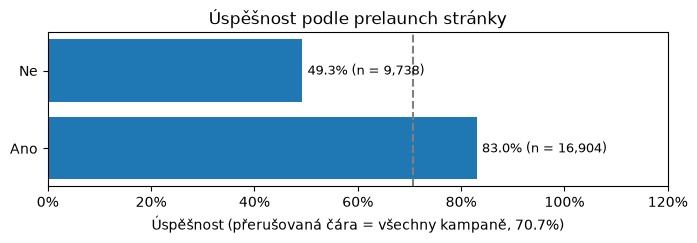

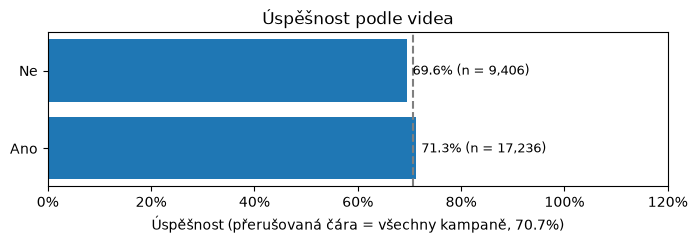

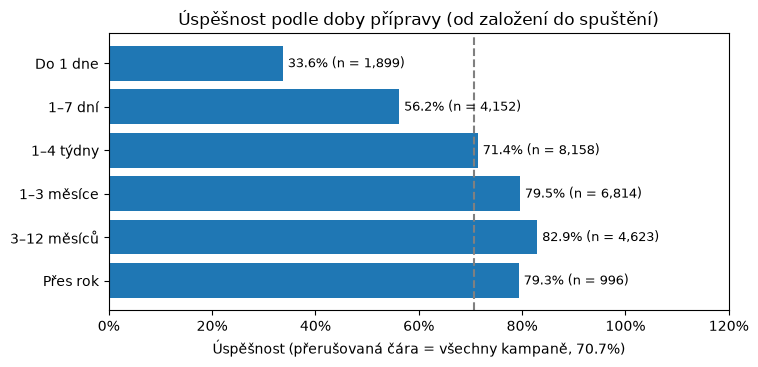

In [15]:
preparation = finished.assign(
    prelaunch=finished["prelaunch_activated"].str.strip().str.lower().map({"true": "Ano", "false": "Ne"}),
    has_video=finished["video"].str.strip().str.lower().isin(["", "null"]).map({True: "Ne", False: "Ano"}),
    preparation_days=(finished["launched_at"] - finished["created_at"]).dt.total_seconds() / 86_400,
)

for column, title in [
    ("prelaunch", "Úspěšnost podle prelaunch stránky"),
    ("has_video", "Úspěšnost podle videa"),
]:
    summary = preparation.groupby(column)["success"].agg(n="size", rate="mean").reindex(["Ne", "Ano"])
    show_success_chart(summary, title)

preparation_bands = ["Do 1 dne", "1–7 dní", "1–4 týdny", "1–3 měsíce", "3–12 měsíců", "Přes rok"]
preparation_group = pd.cut(
    preparation["preparation_days"], [0, 1, 7, 30, 90, 365, np.inf], labels=preparation_bands, include_lowest=True
)
preparation_summary = preparation.groupby(preparation_group, observed=False)["success"].agg(n="size", rate="mean")
show_success_chart(preparation_summary, "Úspěšnost podle doby přípravy (od založení do spuštění)")

Z grafů vyplývá:
- Prelaunch má výrazný vliv: s prelaunch stránkou uspěje 83 % kampaní, bez ní pouze 49 %.
- S delší přípravou úspěšnost roste. Kampaně spuštěné do jednoho dne od založení uspějí přibližně v jedné třetině případů, kampaně připravované 3–12 měsíců v 83 %. Prelaunch a doba přípravy spolu souvisí ([3.9](#s3-9)) a oba pravděpodobně odrážejí, jak pečlivě tvůrce kampaň připravil.
- U videa je rozdíl překvapivě téměř nulový (70 % oproti 71 %). Kampaně s videem však mívají vyšší cíle ([3.9](#s3-9)), takže se oba vlivy mohou vzájemně rušit. Video v modelu ponecháváme a jeho využití necháváme na modelu.

<a id="s2-8"></a>
### 2.8 Den a hodina spuštění

Den i hodinu spuštění uvádíme v UTC. Většina kampaní pochází z USA, kde je čas posunutý o 5–8 hodin.

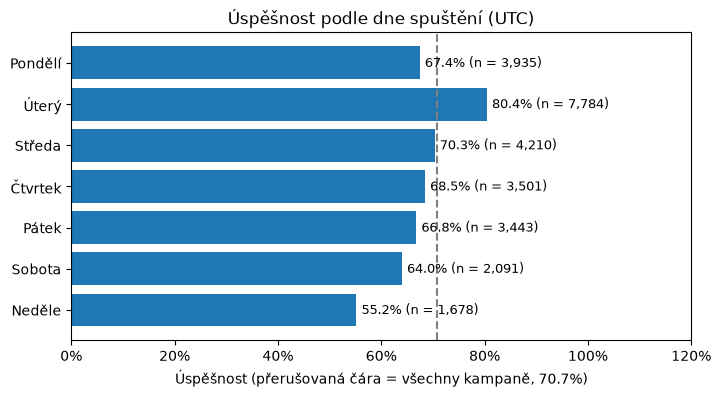

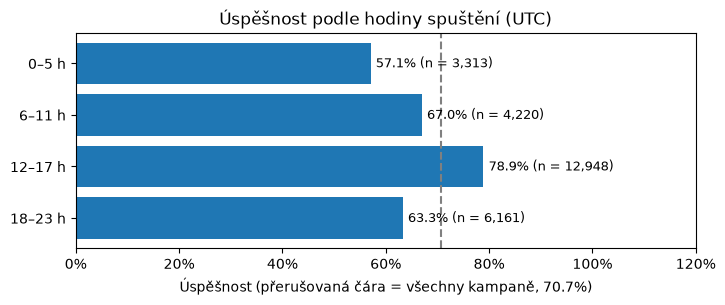

In [16]:
weekday_names = ["Pondělí", "Úterý", "Středa", "Čtvrtek", "Pátek", "Sobota", "Neděle"]
weekday_summary = finished.groupby(finished["launched_at"].dt.day_of_week)["success"].agg(n="size", rate="mean")
weekday_summary.index = weekday_names
show_success_chart(weekday_summary, "Úspěšnost podle dne spuštění (UTC)")

hour_bands = ["0–5 h", "6–11 h", "12–17 h", "18–23 h"]
hour_group = pd.cut(finished["launched_at"].dt.hour, [-1, 5, 11, 17, 23], labels=hour_bands)
hour_summary = finished.groupby(hour_group, observed=False)["success"].agg(n="size", rate="mean")
show_success_chart(hour_summary, "Úspěšnost podle hodiny spuštění (UTC)")

Z grafů vyplývá:
- Úterý se výrazně liší od ostatních dnů: spouští se v něm téměř dvakrát více kampaní než v ostatní pracovní dny a uspěje jich 80 %. Nejnižší úspěšnost mají víkendové kampaně, v neděli pouze 55 %.
- Kampaně spuštěné mezi 12. a 17. hodinou UTC (v USA dopoledne, v Evropě odpoledne) uspějí v 79 % případů, kampaně spuštěné v noci (0–5 h) v 57 %.
- Samotný den nebo hodina úspěch pravděpodobně nezpůsobují, spíše vypovídají o tom, kdo kampaň spouští. Zkušení tvůrci a firmy spuštění plánují, zatímco víkendová a noční spuštění budou častěji připadat na začínající tvůrce.

Den v týdnu je součástí modelu. Hodinu spuštění jsme do modelu nezařadili, protože tento vzor jsme odhalili až po vyhodnocení na testovací sadě ([sekce 7](#s7)).

<a id="s2-9"></a>
### 2.9 Opakovaní tvůrci

Kampaně každého tvůrce v roce 2025 očíslujeme podle data spuštění (1., 2., 3. kampaň atd.). ID tvůrce získáváme z JSON sloupce `creator`.

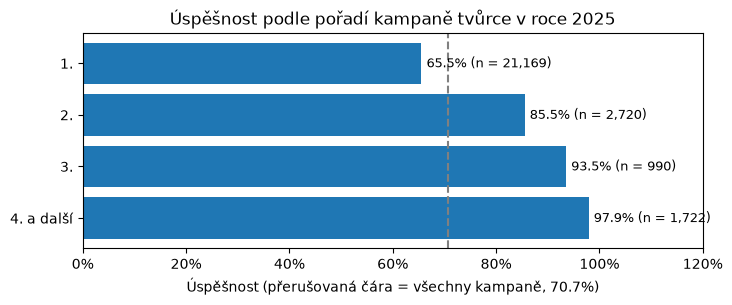

In [17]:
def creator_id(value):
    """ID tvůrce z JSON sloupce creator, nebo None, když chybí nebo je nečitelné."""
    try:
        creator = json.loads(value)
        if isinstance(creator, dict):
            value = creator.get("id")
            if isinstance(value, int) and not isinstance(value, bool) and value > 0:
                return str(value)
    except (TypeError, json.JSONDecodeError):
        pass
    return None


with_creator = projects.assign(creator_key=projects["creator"].map(creator_id)).dropna(subset=["creator_key"])
with_creator = with_creator.sort_values("launched_at")
with_creator["campaign_order"] = with_creator.groupby("creator_key").cumcount() + 1

finished_with_creator = with_creator.loc[with_creator["success"].notna()]
order_group = finished_with_creator["campaign_order"].clip(upper=4).map({1: "1.", 2: "2.", 3: "3.", 4: "4. a další"})
order_summary = finished_with_creator.groupby(order_group)["success"].agg(n="size", rate="mean")
show_success_chart(order_summary, "Úspěšnost podle pořadí kampaně tvůrce v roce 2025")

Tvůrci, kteří spouštějí více kampaní, uspívají výrazně častěji. První kampaň tvůrce v roce 2025 uspěje v 66 % případů, druhá v 86 %, třetí v 94 % a čtvrtá a další v 98 %. Pravděpodobně jde převážně o zavedená vydavatelství a autory, kteří vydávají pravidelně.

Z toho plynou tři důsledky:
- Jako příznak tuto informaci nepoužíváme, protože ji z dostupných dat nezjistíme spolehlivě. Ani po stažení všech dostupných snapshotů včetně starších let by počet předchozích kampaní tvůrce nebyl úplný, protože snapshoty nezachycují všechny projekty. Navíc bychom museli určit, kolik kampaní měl tvůrce právě v okamžiku spuštění posuzované kampaně, a JSON `creator` takový údaj neobsahuje.
- Jde o hlavní důvod, proč data dělíme podle tvůrců ([3.5](#s3-5)). Pokud by měl tvůrce kampaně v trénovací i testovací sadě, model by si jej mohl „zapamatovat“ a výsledek na testovací sadě by byl nadhodnocený.
- Část této informace zachycují LLM příznaky ([sekce 5](#s5)), například „pokračování série“ nebo „známá značka“ v názvu.

<a id="s3"></a>
## 3. Preprocessing

Cílem je odhadnout výsledek v okamžiku spuštění kampaně, do modelu proto smí vstupovat pouze údaje, které jsou v té době známé. Všechny údaje však pocházejí z posledního snapshotu, který může zachycovat stav i několik měsíců po spuštění. Cíl, kategorie a datum spuštění by se po spuštění měnit neměly. U videa, prelaunch stránky nebo popisu to z dat ověřit nedokážeme.

<a id="s3-1"></a>
### 3.1 Výběr kampaní

Pracujeme s dokončenými kampaněmi (`successful` = 1, `failed` = 0). Vyřazujeme 7 projektů, u nichž se snapshoty rozcházejí, a 8 kampaní trvajících 61 a více dní. Kickstarter povoluje nejvýše 60 dní ([zdroj](https://updates.kickstarter.com/why-is-funding-all-or-nothing/)), takové kampaně proto považujeme za chybné záznamy. Hranice 61 dní namísto 60 představuje toleranci pro drobné nepřesnosti v uložených časech.

In [18]:
conflicts = finished["snapshot_conflict"]
long_campaigns = finished["duration_days"].ge(61)
model_projects = finished.loc[~conflicts & ~long_campaigns].copy()
print(f"Konfliktní projekty: {conflicts.sum():,}")
print(f"Kampaně alespoň 61 dní: {long_campaigns.sum():,}")
print(f"Pro model zbývá {len(model_projects):,} kampaní.")

Konfliktní projekty: 7
Kampaně alespoň 61 dní: 8
Pro model zbývá 26,627 kampaní.


<a id="s3-2"></a>
### 3.2 Finanční cíl

Cíl převádíme do USD pomocí sloupce `static_usd_rate` ze stejného řádku a logaritmujeme jej (`log1p`), aby velmi vysoké cíle neměly nepřiměřený vliv. Správnost kurzu ověřuje následující kontrola: vybraná částka převedená kurzem `static_usd_rate` odpovídá údaji `usd_pledged`, který uvádí Kickstarter. Původní měnu ponecháváme jako samostatný příznak.

In [19]:
model_projects["static_usd_rate"] = pd.to_numeric(model_projects["static_usd_rate"], errors="coerce")
goal_usd = model_projects["goal"] * model_projects["static_usd_rate"]
model_projects["goal_usd"] = goal_usd.where(
    np.isfinite(goal_usd) & model_projects["goal"].gt(0) & model_projects["static_usd_rate"].gt(0)
)
model_projects["log_goal_usd"] = np.log1p(model_projects["goal_usd"])
display(model_projects[["goal", "currency", "static_usd_rate", "goal_usd", "log_goal_usd"]].head())

,goal,currency,static_usd_rate,goal_usd,log_goal_usd
0,100,USD,1.000000,100.0000,4.615121
1,30000,HKD,0.128692,3860.7603,8.258878
2,15000,USD,1.000000,15000.0000,9.615872
3,1000,USD,1.000000,1000.0000,6.908755
4,9000,USD,1.000000,9000.0000,9.105091


In [20]:
# Kontrola kurzu: vybraná částka převedená kurzem static_usd_rate musí odpovídat sloupci usd_pledged.
pledged = pd.to_numeric(model_projects["pledged"], errors="coerce")
usd_pledged = pd.to_numeric(model_projects["usd_pledged"], errors="coerce")
comparable = pledged.gt(0) & usd_pledged.gt(0)
relative_error = (pledged * model_projects["static_usd_rate"] / usd_pledged - 1).abs()[comparable]
other_currency = comparable & model_projects["currency"].ne("USD")
print(
    f"Shoda převodu s usd_pledged (odchylka do 1 %): {relative_error.le(0.01).mean():.1%} "
    f"z {comparable.sum():,} kampaní, z toho {other_currency.sum():,} v jiné měně než USD"
)

Shoda převodu s usd_pledged (odchylka do 1 %): 100.0% z 25,570 kampaní, z toho 11,711 v jiné měně než USD


<a id="s3-3"></a>
### 3.3 Kategorie, země a další příznaky

Ponecháváme hlavní kategorii, podkategorii a zemi. Podrobnější oblast (`region`) vynecháváme, protože obsahuje mnoho vzácných hodnot a v každé zemi má jiný význam. U videa pouze zjišťujeme, zda je vyplněné. Prelaunch převádíme na hodnoty 1/0.

In [21]:
video = model_projects["video"].str.strip().str.lower()
model_projects["has_video"] = ~video.isin(["", "null"])
prelaunch = model_projects["prelaunch_activated"].str.strip().str.lower()
model_projects["prelaunch"] = prelaunch.map({"true": 1, "false": 0})
display(model_projects[["main_category", "subcategory", "country", "has_video", "prelaunch"]].head())

,main_category,subcategory,country,has_video,prelaunch
0,Games,Tabletop Games,US,False,0
1,Technology,Hardware,HK,True,1
2,Games,Tabletop Games,US,True,1
3,Games,Tabletop Games,US,True,0
4,Publishing,Art Books,US,False,1


<a id="s3-4"></a>
### 3.4 Časové příznaky

Z časových údajů připravíme délku kampaně, dobu přípravy (od založení projektu do spuštění), den v týdnu a měsíc spuštění, vše v UTC. U doby přípravy nevíme, zda tvůrce na kampani po celou dobu pracoval, s úspěchem však souvisí ([2.7](#s2-7)).

In [22]:
model_projects["duration_days"] = model_projects["duration_days"].where(model_projects["duration_days"].gt(0))
preparation_days = (model_projects["launched_at"] - model_projects["created_at"]).dt.total_seconds() / 86_400
model_projects["preparation_days"] = preparation_days.where(preparation_days.ge(0))
model_projects["launch_weekday_utc"] = model_projects["launched_at"].dt.day_of_week
model_projects["launch_month"] = model_projects["launched_at"].dt.month

feature_columns = [
    "log_goal_usd", "currency", "country", "main_category", "subcategory",
    "has_video", "prelaunch", "duration_days", "preparation_days",
    "launch_weekday_utc", "launch_month",
]
model_projects = model_projects.set_index("id")
display(model_projects[feature_columns].head())
display(model_projects[feature_columns].isna().sum().rename("Chybí").to_frame())

,log_goal_usd,currency,country,main_category,subcategory,has_video,prelaunch,duration_days,preparation_days,launch_weekday_utc,launch_month
id,,,,,,,,,,,
19795,4.615121,USD,US,Games,Tabletop Games,False,0,7.000000,0.917975,0,11
118563,8.258878,HKD,HK,Technology,Hardware,True,1,30.000000,78.279664,3,3
164004,9.615872,USD,US,Games,Tabletop Games,True,1,30.000000,35.911748,2,10
283033,6.908755,USD,US,Games,Tabletop Games,True,0,15.041667,0.691458,5,10
298151,9.105091,USD,US,Publishing,Art Books,False,1,30.000000,106.821898,4,8


,Chybí
log_goal_usd,0
currency,0
country,0
main_category,0
subcategory,0
has_video,0
prelaunch,0
duration_days,0
preparation_days,0
launch_weekday_utc,0


<a id="s3-5"></a>
### 3.5 Rozdělení na trénovací a testovací sadu podle tvůrců

Tvůrce náhodně rozdělujeme v poměru přibližně 85 : 15 do trénovací a testovací sady (seed 42). Všechny kampaně jednoho tvůrce jsou vždy ve stejné sadě, důvod popisuje [2.9](#s2-9).

Výjimku tvoří 478 kampaní, na jejichž textech jsme navrhovali a ladili LLM příznaky ([5.1](#s5-1)). Tyto kampaně i jejich tvůrce zařazujeme vždy do trénovací sady, aby testovací sada nebyla závislá ani na návrhu AI části. Ostatní tvůrce dělíme náhodně tak, aby poměr zůstal přibližně 85 : 15. 41 projektů nemá čitelné ID tvůrce, každý z nich proto tvoří samostatnou skupinu. ID tvůrce slouží pouze k rozdělení dat, vstupem modelu není.

Samostatnou validační sadu nevytváříme, protože hyperparametry ladíme křížovou validací na trénovací sadě ([sekce 4](#s4)). Testovací sadu používáme jen jednou, při závěrečném vyhodnocení ([sekce 6](#s6)). Průzkum dat v [sekci 2](#s2) zahrnoval i testovací kampaně, testovací sada proto není na průzkumu zcela nezávislá. Průzkum však sloužil pouze k výběru příznaků, o jejich přínosu rozhoduje až křížová validace.

Původně jsme zvažovali časové rozdělení (trénování na lednu až říjnu, testování na listopadu a prosinci). Testovací sada by však obsahovala pouze dva měsíce, navíc neúplné (vysoký podíl kampaní `live`), a příznak měsíce by v ní nabýval hodnot, které model při trénování neviděl. Zda náhodné rozdělení nezkresluje výsledky, ověřujeme v [6.7](#s6-7).

In [23]:
# Funkce creator_id je definovaná v sekci 2.9.
creator_ids = model_projects["creator"].map(creator_id)
groups = "creator:" + creator_ids
missing_creators = creator_ids.isna()
groups.loc[missing_creators] = "project:" + model_projects.index[missing_creators]
print(f"Projektů bez čitelného ID tvůrce: {missing_creators.sum():,}")

# Projekty, na jejichž textech jsme navrhovali a ladili LLM příznaky (discovery a pilot v 02_llm_features.ipynb), patří vždy do tréninku, a s nimi celá skupina jejich tvůrce.
ai_dir = prepared_dir.parent / "ai"
design_ids = set(pd.concat([
    pd.read_csv(ai_dir / "discovery_sample_ids.csv", dtype=str)["id"],
    pd.read_csv(ai_dir / "pilot_sample_ids.csv", dtype=str)["id"],
]).str.strip()) & set(model_projects.index)
design_groups = set(groups.loc[list(design_ids)])
print(f"Projektů z návrhu AI části: {len(design_ids):,} · jejich skupin tvůrců: {len(design_groups):,}")

rng = np.random.default_rng(42)
group_ids = rng.permutation(groups.unique())
train_end = int(len(group_ids) * 0.85)
other_groups = [group for group in group_ids if group not in design_groups]
n_other_train = train_end - len(design_groups)
train_groups = design_groups | set(other_groups[:n_other_train])
test_groups = set(other_groups[n_other_train:])

train_mask = groups.isin(train_groups)
test_mask = groups.isin(test_groups)

X_train = model_projects.loc[train_mask, feature_columns].copy()
X_test = model_projects.loc[test_mask, feature_columns].copy()
y_train = model_projects.loc[train_mask, "success"].astype("int8")
y_test = model_projects.loc[test_mask, "success"].astype("int8")

# Skupiny tvůrců pro trénink potřebujeme i v křížové validaci (sekce 4).
groups_train = groups.loc[train_mask]

split_summary = pd.DataFrame({
    "Počet": [len(y_train), len(y_test)],
    "Podíl úspěšných": [y_train.mean(), y_test.mean()],
}, index=["Trénink", "Test"])
display(split_summary)

split_months = pd.DataFrame({
    "Trénink": model_projects.loc[train_mask, "launch_month"].value_counts(),
    "Test": model_projects.loc[test_mask, "launch_month"].value_counts(),
}).fillna(0).astype(int).sort_index()
display(split_months)

assert train_groups.isdisjoint(test_groups)
assert design_ids <= set(X_train.index)
assert len(X_train) + len(X_test) == len(model_projects)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)

Projektů bez čitelného ID tvůrce: 41
Projektů z návrhu AI části: 478 · jejich skupin tvůrců: 477


,Počet,Podíl úspěšných
Trénink,22734,0.70841
Test,3893,0.69869


,Trénink,Test
launch_month,,
1,1761,309
2,1870,338
3,1954,301
4,1917,329
5,1909,376
6,2041,313
7,1902,333
8,1770,289
9,2085,375


<a id="s3-6"></a>
### 3.6 Výstup preprocessingu

Po výběru máme 26 627 kampaní s 11 příznaky, rozdělených podle tvůrců na trénovací a testovací sadu. Následuje přehled velikosti sad, náhodná ukázka pěti trénovacích kampaní (jeden sloupec odpovídá jedné kampani, `success` je připojen pouze pro přehled, jinak je uložen v `y_train`) a počty chybějících hodnot. Poslední tabulka uvádí datové typy příznaků, kategorie převádíme na typ `category` až v [4.1](#s4-1).

In [24]:
print("Dataset summary")
dataset_summary = pd.DataFrame({
    "Počet kampaní": [len(X_train), len(X_test)],
    "Počet příznaků": [X_train.shape[1], X_test.shape[1]],
    "Úspěšné kampaně": [int(y_train.sum()), int(y_test.sum())],
}, index=["Trénink", "Test"])
display(dataset_summary)


Dataset summary


,Počet kampaní,Počet příznaků,Úspěšné kampaně
Trénink,22734,11,16105
Test,3893,11,2720


In [25]:
print("Náhled datasetu")
training_preview = X_train.join(y_train.rename("success"))
display(training_preview.sample(5, random_state=42).T)

Náhled datasetu


id,103225812,1746453407,392075881,528523503,1196415338
log_goal_usd,9.678139,9.21044,9.794777,9.350189,6.284559
currency,EUR,USD,GBP,USD,MXN
country,FR,US,GB,US,MX
main_category,Technology,Design,Photography,Publishing,Games
subcategory,Apps,Product Design,Photobooks,Literary Spaces,Video Games
has_video,True,True,True,False,False
prelaunch,1,0,1,0,0
duration_days,28.540556,45.0,27.726354,59.299016,18.0
preparation_days,30.91191,10.955475,158.864387,30.037766,0.095243
launch_weekday_utc,4,0,1,1,5


In [26]:
print("Chybějící hodnoty")
missing_by_split = pd.DataFrame({
    "Trénink": X_train.isna().sum(),
    "Test": X_test.isna().sum(),
})
display(missing_by_split)

Chybějící hodnoty


,Trénink,Test
log_goal_usd,0,0
currency,0,0
country,0,0
main_category,0,0
subcategory,0,0
has_video,0,0
prelaunch,0,0
duration_days,0,0
preparation_days,0,0
launch_weekday_utc,0,0


In [27]:
print("Datové typy příznaků")
display(X_train.dtypes.astype(str).rename("Typ").to_frame())

Datové typy příznaků


,Typ
log_goal_usd,float64
currency,str
country,str
main_category,str
subcategory,str
has_video,bool
prelaunch,int64
duration_days,float64
preparation_days,float64
launch_weekday_utc,int32


<a id="s3-7"></a>
### 3.7 Význam jednotlivých sloupců

| Sloupec | Vznik a důvod použití |
| --- | --- |
| `log_goal_usd` | Cíl převedený do USD a logaritmovaný (`log1p`). Vyšší cíl znamená nižší šanci na úspěch ([2.3](#s2-3)). |
| `currency` | Původní měna jako kategorie. |
| `country` | Země kampaně, může zachytit rozdíly mezi trhy. |
| `main_category`, `subcategory` | Hlavní kategorie a podkategorie z JSONu `category`. Úspěšnost se mezi nimi výrazně liší ([2.2](#s2-2)). |
| `has_video` | Zda je vyplněné video. |
| `prelaunch` | Zda měla kampaň prelaunch stránku (1/0). |
| `duration_days` | Délka kampaně ve dnech (ukončení − spuštění). |
| `preparation_days` | Počet dní od založení projektu do spuštění. |
| `launch_weekday_utc` | Den v týdnu spuštění v UTC (0 = pondělí, 6 = neděle). |
| `launch_month` | Měsíc spuštění (1–12). |

Cílová proměnná `success` má hodnotu 1 pro `successful` a 0 pro `failed`.

Do modelu záměrně nezahrnujeme:
- vybranou částku, počet podporovatelů, procento splnění cíle a `spotlight`, protože popisují průběh nebo výsledek kampaně (`spotlight` dokonce přesně odpovídá úspěchu),
- `staff_pick`, protože nevíme, zda kampaň toto označení získala před spuštěním, nebo až v jeho průběhu,
- údaje o tvůrci: ID by umožnilo zapamatování tvůrců a `backing_action_count` (počet projektů, které tvůrce podpořil) odpovídá až datu snapshotu,
- `region` ([3.3](#s3-3)),
- název a popis přímo. Ty zpracovává jazykový model ([sekce 5](#s5)).

<a id="s3-8"></a>
### 3.8 Další příprava pro model

Chybějící hodnoty a textové kategorie zatím ponecháváme. Jejich doplnění, kódování a škálování provádí pipeline v [sekci 4](#s4), která se učí pouze z trénovací části dat.

<a id="s3-9"></a>
### 3.9 Závislosti mezi příznaky (pouze trénovací sada)

Matice ukazuje, jak spolu souvisí jednotlivé dvojice příznaků a jak každý příznak souvisí s výsledkem. Většina příznaků je kategoriálních, proto místo klasické korelace používáme Cramérovo V. To nabývá hodnot od 0 (žádná souvislost) do 1 (jeden příznak zcela určuje druhý). Číselné příznaky (cíl, délka, doba přípravy) jsme pro výpočet rozdělili do pěti stejně početných skupin.

Výpočet provádíme pouze na trénovací sadě. U příznaků s velkým počtem hodnot (podkategorie, země) vychází Cramérovo V systematicky o něco vyšší, protože malé skupiny mají náhodně odchýlené podíly.

In [28]:
from scipy.stats.contingency import association

dependency_data = X_train.copy()
dependency_data["success"] = y_train
for column in ["log_goal_usd", "duration_days", "preparation_days"]:
    dependency_data[column] = pd.qcut(dependency_data[column], 5, duplicates="drop")

dependency_columns = list(dependency_data.columns)
cramers_v = pd.DataFrame(1.0, index=dependency_columns, columns=dependency_columns)
for first in dependency_columns:
    for second in dependency_columns:
        if first != second:
            table = pd.crosstab(dependency_data[first], dependency_data[second])
            cramers_v.loc[first, second] = association(table.to_numpy(), method="cramer")

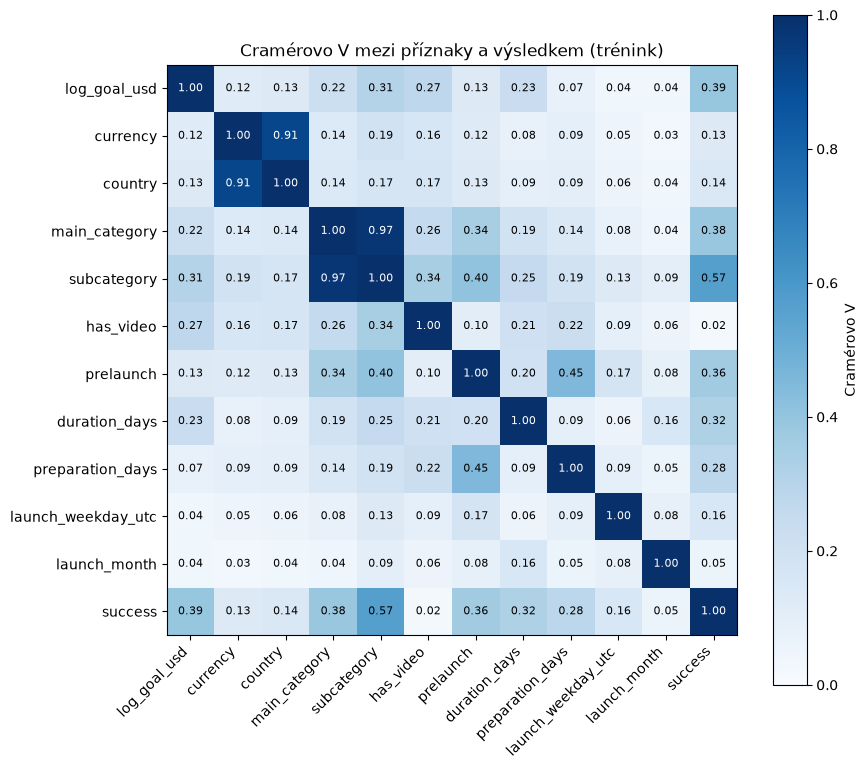

In [29]:
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(cramers_v.astype(float), cmap="Blues", vmin=0, vmax=1)
for row in range(len(dependency_columns)):
    for column in range(len(dependency_columns)):
        value = cramers_v.iloc[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if value > 0.6 else "black")
ax.set_xticks(range(len(dependency_columns)), dependency_columns, rotation=45, ha="right")
ax.set_yticks(range(len(dependency_columns)), dependency_columns)
ax.set_title("Cramérovo V mezi příznaky a výsledkem (trénink)")
fig.colorbar(image, ax=ax, label="Cramérovo V")
plt.tight_layout()
plt.show()

Z matice vyplývá:
- S výsledkem nejvíce souvisí podkategorie (0,57, část této hodnoty je však dána počtem kategorií), dále cíl (0,39), hlavní kategorie (0,38), prelaunch (0,36), délka (0,32) a doba přípravy (0,28).
- Dvě dvojice jsou téměř duplicitní: hlavní kategorie a podkategorie (0,97, podkategorie vždy patří do jediné hlavní kategorie) a měna a země (0,91, země téměř vždy určuje měnu, výjimkou jsou zejména státy eurozóny).
- Dále spolu souvisí prelaunch a doba přípravy (0,45) a video a výše cíle (0,27). Druhá souvislost vysvětluje, proč samotné video úspěch nerozlišuje ([2.7](#s2-7)).

Duplicitní příznaky nevyřazujeme. Logistická regrese používá regularizaci a stromové modely si mezi podobnými příznaky vybírají samy. Kontrola v [4.6](#s4-6) ukazuje, že model bez země nebo bez měny dosahuje prakticky stejného AUC. Ponechání obou příznaků tedy výsledek nezhoršuje.

<a id="s4"></a>
## 4. Modely bez LLM příznaků (varianta A)

V této sekci trénujeme a ladíme modely pouze na 11 příznacích z preprocessingu. Výsledek slouží jako základ pro srovnání s variantami, které obsahují LLM příznaky.

Porovnáváme tři modely:
1. Referenční model, který vždy předpoví „úspěch“. Každý skutečný model jej musí překonat.
2. Logistická regrese: jednoduchý lineární model, jehož fungování lze dobře vysvětlit.
3. Gradient boosting (`HistGradientBoostingClassifier`): stromový model, který zachytí nelineární vztahy a interakce, například že vysoký cíl v některých kategoriích snižuje úspěšnost více než v jiných ([2.4](#s2-4)). Na tabulkových datech obvykle dosahuje nejlepších výsledků a je přímo součástí scikit-learn.

Zvažovali jsme i další modely. SVM je na 22 tisících řádků s mnoha one-hot sloupci pomalé, kNN trpí tím, že vzdálenosti v prostoru se stovkami sloupců nejsou vypovídající, a naivní Bayes předpokládá nezávislost příznaků, které však spolu souvisí ([3.9](#s3-9)). Neuronová síť (MLP) na tabulkových datech obvykle nepřekoná gradient boosting a obtížněji se ladí. XGBoost, LightGBM a CatBoost pracují na stejném principu jako `HistGradientBoostingClassifier`, vyžadují však další balíček.

Hlavní metrikou je ROC AUC. Úspěšných kampaní je 70 %, accuracy 70 % tedy dosáhne i model, který vždy předpoví „úspěch“. ROC AUC měří, jak dobře model seřadí úspěšné kampaně před neúspěšné, a nezávisí na volbě prahu. Accuracy uvádíme rovněž, protože ji vyžaduje zadání. Práh volíme samostatně tak, aby model zachytil obě třídy ([4.7](#s4-7)).

Testovací sadu v této sekci nepoužíváme, veškeré ladění probíhá křížovou validací na trénovací sadě.

<a id="s4-1"></a>
### 4.1 Typy sloupců

Modely potřebují rozlišit číselné a kategoriální příznaky. Den v týdnu a měsíc považujeme za kategorie.

In [30]:
numeric_columns = ["log_goal_usd", "duration_days", "preparation_days"]
binary_columns = ["has_video", "prelaunch"]
categorical_columns = [
    "currency", "country", "main_category", "subcategory",
    "launch_weekday_utc", "launch_month",
]

# Kontrola, že jsme žádný příznak nevynechali ani nezopakovali.
assert sorted(numeric_columns + binary_columns + categorical_columns) == sorted(feature_columns)

Kategoriální sloupce převedeme na typ `category` se seznamem hodnot z trénovací sady. Hodnota, která se vyskytuje pouze v testovací sadě (např. vzácná podkategorie), se změní na chybějící hodnotu, se kterou modely umí pracovat. Převod probíhá mimo pipeline, model se z něj však nic neučí: využívá se pouze seznam možných hodnot, četnosti ani cílová proměnná se při něm nepoužívají.

In [31]:
for column in categorical_columns:
    train_values = sorted(X_train[column].unique())
    X_train[column] = pd.Categorical(X_train[column], categories=train_values)
    X_test[column] = pd.Categorical(X_test[column], categories=train_values)

print("Počet různých hodnot v kategoriálních sloupcích:")
display(X_train[categorical_columns].nunique().rename("Hodnot").to_frame())

Počet různých hodnot v kategoriálních sloupcích:


,Hodnot
currency,15
country,25
main_category,15
subcategory,160
launch_weekday_utc,7
launch_month,12


<a id="s4-2"></a>
### 4.2 Křížová validace

Trénovací sadu rozdělíme na 5 foldů. Model se pětkrát natrénuje na čtyřech částech a vyhodnotí na páté, výsledkem je průměr a směrodatná odchylka z pěti opakování.

Používáme `StratifiedGroupKFold`:
- group: kampaně jednoho tvůrce jsou vždy ve stejném foldu, stejně jako při rozdělení na trénovací a testovací sadu,
- stratified: každý fold má podobný podíl úspěšných kampaní.

Foldy jsou shodné pro všechny modely i varianty, srovnání je tedy férové.

In [32]:
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

In [33]:
fold_rows = []
for fold_number, (fit_index, check_index) in enumerate(cv.split(X_train, y_train, groups_train), start=1):
    fold_rows.append({
        "Fold": fold_number,
        "Kampaní ve foldu": len(check_index),
        "Podíl úspěšných": f"{y_train.iloc[check_index].mean():.1%}",
    })
display(pd.DataFrame(fold_rows).set_index("Fold"))

,Kampaní ve foldu,Podíl úspěšných
Fold,,
1,4547,70.8%
2,4547,70.8%
3,4547,70.8%
4,4547,70.8%
5,4546,70.9%


<a id="s4-3"></a>
### 4.3 Referenční model

`DummyClassifier` vždy předpoví nejčastější třídu, tedy „úspěch“. Jeho ROC AUC je 0,5 (odpovídá náhodě) a accuracy se rovná podílu úspěšných kampaní.

In [34]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

scoring = ["roc_auc", "accuracy"]

dummy_scores = cross_validate(
    DummyClassifier(strategy="most_frequent"),
    X_train, y_train, groups=groups_train, cv=cv, scoring=scoring,
)
print(f"Referenční model · ROC AUC: {dummy_scores['test_roc_auc'].mean():.3f} · accuracy: {dummy_scores['test_accuracy'].mean():.3f}")

Referenční model · ROC AUC: 0.500 · accuracy: 0.708


<a id="s4-4"></a>
### 4.4 Logistická regrese

Logistická regrese vyžaduje číselné vstupy na srovnatelné škále. Proto:
- číselné sloupce doplníme mediánem (pro případ chybějících hodnot) a standardizujeme, aby velikost hodnot neovlivňovala regularizaci,
- kategorie převedeme one-hot kódováním na sloupce 0/1, hodnotu, která se při trénování nevyskytla, kódování ignoruje,
- binární sloupce pouze doplníme nejčastější hodnotou.

Všechny úpravy jsou součástí pipeline, v každém foldu se tedy učí pouze z trénovací části a z validační části se do nich nedostane žádná informace.

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

number_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

logreg_preprocessing = ColumnTransformer([
    ("numbers", number_steps, numeric_columns),
    ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
    ("binary", SimpleImputer(strategy="most_frequent"), binary_columns),
])

In [36]:
from sklearn.linear_model import LogisticRegression

logreg_pipeline = Pipeline([
    ("preprocessing", logreg_preprocessing),
    ("model", LogisticRegression(max_iter=2000)),
])

Při ladění logistické regrese je hlavním hyperparametrem síla regularizace `C`. Malé `C` drží koeficienty u nuly (jednodušší model), velké jim ponechává volnost. Zkoušíme hodnoty 0,001 až 100 na logaritmické škále. Dále zkoušíme `class_weight` bez vah a s hodnotou `"balanced"`, která neúspěšným kampaním přiřazuje vyšší váhu, protože jsou méně početné.

`RandomizedSearchCV` vyzkouší 20 náhodných kombinací, každou vyhodnotí pětinásobnou křížovou validací a vybere kombinaci s nejvyšším průměrným ROC AUC (`refit="roc_auc"`). Náhodné prohledávání jsme zvolili namísto úplné mřížky především kvůli gradient boostingu, u něhož ladíme pět hyperparametrů a úplná mřížka by byla výpočetně zbytečně náročná.

In [37]:
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV

logreg_search_space = {
    "model__C": loguniform(0.001, 100),
    "model__class_weight": [None, "balanced"],
}

logreg_search = RandomizedSearchCV(
    logreg_pipeline,
    logreg_search_space,
    n_iter=20,
    scoring=scoring,
    refit="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
)

In [38]:
import time

started = time.perf_counter()
logreg_search.fit(X_train, y_train, groups=groups_train)
print(f"Ladění logistické regrese trvalo {time.perf_counter() - started:.0f} s.")

Ladění logistické regrese trvalo 9 s.


Pět nejlepších kombinací. Pokud by nejlepší hodnota `C` ležela na okraji zkoušeného rozsahu, rozsah bychom rozšířili.

In [39]:
def top_results(search, count=5):
    """Tabulka nejlepších kombinací z RandomizedSearchCV seřazená podle ROC AUC."""
    results = pd.DataFrame(search.cv_results_)
    parameter_columns = [column for column in results.columns if column.startswith("param_")]
    table = results[parameter_columns + ["mean_test_roc_auc", "std_test_roc_auc", "mean_test_accuracy"]]
    table = table.rename(columns=lambda column: column.replace("param_model__", "").replace("param_", ""))
    return table.sort_values("mean_test_roc_auc", ascending=False).head(count).round(4)


display(top_results(logreg_search))

,C,class_weight,mean_test_roc_auc,std_test_roc_auc,mean_test_accuracy
17,1.2357,balanced,0.8902,0.0029,0.8094
2,0.9847,NaN,0.8902,0.0030,0.8313
11,1.1436,NaN,0.8902,0.0029,0.8312
18,0.3725,balanced,0.8902,0.0031,0.8084
13,0.4206,NaN,0.8902,0.0031,0.8314


<a id="s4-5"></a>
### 4.5 Gradient boosting

`HistGradientBoostingClassifier` postupně staví stovky malých rozhodovacích stromů, z nichž každý opravuje chyby předchozích. Nevyžaduje škálování ani one-hot kódování, kategorie typu `category` zpracovává přímo (`categorical_features="from_dtype"`) a pracuje i s chybějícími hodnotami.

Parametr `early_stopping` jsme vypnuli a počet stromů ladíme sami. Automatické zastavení si totiž vyčleňuje náhodnou část dat, která by nerespektovala skupiny tvůrců.

In [40]:
from sklearn.ensemble import HistGradientBoostingClassifier

boosting_model = HistGradientBoostingClassifier(
    categorical_features="from_dtype",
    early_stopping=False,
    random_state=42,
)

Při ladění gradient boostingu zkoušíme pět hyperparametrů, které výsledek ovlivňují nejvíce:
- `learning_rate`: velikost kroku každého stromu (menší hodnota znamená opatrnější učení, ale více stromů),
- `max_iter`: počet stromů,
- `max_leaf_nodes`: velikost jednoho stromu,
- `min_samples_leaf`: minimální počet kampaní v listu (vyšší hodnota snižuje riziko přeučení),
- `l2_regularization`: penalizace příliš výrazných hodnot v listech.

Zkoušíme 25 kombinací se stejnými foldy. Rozsahy jsme jednou upravili, protože v prvním běhu ležely nejlepší hodnoty na okraji (`learning_rate` ≈ 0,022 při spodní hranici 0,02, `min_samples_leaf` = 183 při horní hranici 200). Spodní hranici `learning_rate` jsme snížili na 0,01 a horní hranici `min_samples_leaf` zvýšili na 500. Výsledek se téměř nezměnil (rozdíl pod 0,002 AUC). Nejlepší `learning_rate` (přibližně 0,012) leží i po rozšíření blízko spodní hranice, rozdíly mezi kombinacemi jsou však v řádu tisícin AUC, a další rozšíření by proto výsledek prakticky neovlivnilo. Stejné rozsahy používáme i pro varianty s LLM příznaky.

In [41]:
from scipy.stats import randint

boosting_search_space = {
    "learning_rate": loguniform(0.01, 0.3),
    "max_iter": randint(100, 600),
    "max_leaf_nodes": randint(15, 64),
    "min_samples_leaf": randint(20, 500),
    "l2_regularization": loguniform(0.001, 10),
}

boosting_search = RandomizedSearchCV(
    boosting_model,
    boosting_search_space,
    n_iter=25,
    scoring=scoring,
    refit="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
)

In [42]:
started = time.perf_counter()
boosting_search.fit(X_train, y_train, groups=groups_train)
print(f"Ladění gradient boostingu trvalo {time.perf_counter() - started:.0f} s.")

Ladění gradient boostingu trvalo 25 s.


In [43]:
display(top_results(boosting_search))

,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,mean_test_roc_auc,std_test_roc_auc,mean_test_accuracy
18,1.6173,0.0129,426,23,363,0.9014,0.0024,0.8417
22,0.0211,0.0124,506,38,312,0.9013,0.0024,0.8431
15,0.0023,0.0195,289,54,232,0.9007,0.0021,0.8420
19,0.0380,0.0271,162,25,100,0.9005,0.0025,0.8420
10,0.0084,0.0227,543,21,447,0.9004,0.0028,0.8420


<a id="s4-6"></a>
### 4.6 Srovnání modelů (křížová validace)

Pro každý model uvádíme nejlepší kombinaci hyperparametrů: průměr přes 5 foldů a směrodatnou odchylku. Rozdíly menší než přibližně jedna směrodatná odchylka nepovažujeme za průkazné.

In [44]:
def best_scores(search):
    """ROC AUC a accuracy nejlepší kombinace z křížové validace."""
    best = search.best_index_
    results = search.cv_results_
    return {
        "ROC AUC (průměr)": results["mean_test_roc_auc"][best],
        "ROC AUC (odchylka)": results["std_test_roc_auc"][best],
        "Accuracy (průměr)": results["mean_test_accuracy"][best],
    }


comparison_a = pd.DataFrame({
    "Referenční model": {
        "ROC AUC (průměr)": dummy_scores["test_roc_auc"].mean(),
        "ROC AUC (odchylka)": dummy_scores["test_roc_auc"].std(),
        "Accuracy (průměr)": dummy_scores["test_accuracy"].mean(),
    },
    "Logistická regrese": best_scores(logreg_search),
    "Gradient boosting": best_scores(boosting_search),
}).T.round(3)
display(comparison_a)

,ROC AUC (průměr),ROC AUC (odchylka),Accuracy (průměr)
Referenční model,0.500,0.000,0.708
Logistická regrese,0.890,0.003,0.809
Gradient boosting,0.901,0.002,0.842


Výsledky:
- Oba modely referenční model jednoznačně překonávají: AUC 0,89–0,90 oproti 0,50, accuracy 0,81–0,84 oproti 0,71.
- Gradient boosting je o něco lepší (0,901 oproti 0,890). Rozdíl 0,011 několikanásobně převyšuje směrodatnou odchylku mezi foldy (0,002–0,003). Gradient boosting pravděpodobně využívá interakce, například cíl × kategorie.
- Na volbě hyperparametrů příliš nezáleží, nejlepší kombinace se liší v řádu tisícin. Výsledek tedy není závislý na jednom konkrétním nastavení.
- Logistická regrese má nižší accuracy (0,81) kvůli `class_weight="balanced"`, s nímž při prahu 0,5 častěji předpovídá neúspěch. Podle AUC jsou obě nastavení vah srovnatelná, liší se pouze poloha optimálního prahu, který volíme samostatně ([4.7](#s4-7)).
- AUC 0,90 je poměrně vysoké, proto následující kontrola ověřuje, zda některý příznak neprozrazuje výsledek.

Kontroly: AUC jednotlivých příznaků samostatně (gradient boosting s výchozím nastavením, stejné foldy) a AUC nejlepšího gradient boostingu bez země nebo bez měny ([3.9](#s3-9)).

In [45]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

single_feature_auc = {}
for column in feature_columns:
    scores = cross_val_score(
        HistGradientBoostingClassifier(categorical_features="from_dtype", early_stopping=False, random_state=42),
        X_train[[column]], y_train, groups=groups_train, cv=cv, scoring="roc_auc", n_jobs=-1,
    )
    single_feature_auc[column] = scores.mean()
display(pd.Series(single_feature_auc, name="ROC AUC samotného příznaku").sort_values(ascending=False).round(3).to_frame())

,ROC AUC samotného příznaku
subcategory,0.830
log_goal_usd,0.749
main_category,0.732
duration_days,0.722
prelaunch,0.690
preparation_days,0.665
launch_weekday_utc,0.591
country,0.561
currency,0.558
launch_month,0.529


In [46]:
drop_check = {}
for dropped in [None, "country", "currency"]:
    columns = [column for column in X_train.columns if column != dropped]
    scores = cross_val_score(
        clone(boosting_search.best_estimator_), X_train[columns], y_train,
        groups=groups_train, cv=cv, scoring="roc_auc", n_jobs=-1,
    )
    drop_check["všechny příznaky" if dropped is None else f"bez {dropped}"] = scores.mean()
display(pd.Series(drop_check, name="ROC AUC (křížová validace)").round(4).to_frame())

,ROC AUC (křížová validace)
všechny příznaky,0.9014
bez country,0.9009
bez currency,0.9014


Výsledky kontrol:
- Žádný příznak sám o sobě výsledek neprozrazuje, hodnota blízká 1 by naznačovala únik informace. Nejsilnější je podkategorie (AUC 0,83), dále cíl (0,75), hlavní kategorie (0,73), délka (0,72) a prelaunch (0,69), což odpovídá průzkumu dat.
- Bez země klesne AUC o 0,0005, bez měny se nezmění. Každý z obou příznaků tedy vedle druhého téměř nic nepřidává, jejich ponechání však ani neškodí ([3.9](#s3-9)).

<a id="s4-7"></a>
### 4.7 ROC křivka, práh a confusion matrix

Pro každou trénovací kampaň použijeme předpověď modelu, který ji při trénování neviděl (`cross_val_predict`, v každém foldu se model učí na zbylých čtyřech). Z těchto předpovědí sestrojíme ROC křivku a zvolíme práh.

Hyperparametry byly vybrány na stejných foldech, skóre proto může být nepatrně nadhodnocené. Na volbu prahu to vliv nemá, nestranný odhad poskytne až testovací sada.

In [47]:
from sklearn.model_selection import cross_val_predict

logreg_cv_proba = cross_val_predict(
    logreg_search.best_estimator_, X_train, y_train,
    groups=groups_train, cv=cv, method="predict_proba", n_jobs=-1,
)[:, 1]

boosting_cv_proba = cross_val_predict(
    boosting_search.best_estimator_, X_train, y_train,
    groups=groups_train, cv=cv, method="predict_proba", n_jobs=-1,
)[:, 1]

ROC křivka zobrazuje pro všechny možné prahy podíl zachycených úspěšných kampaní (osa y) a podíl neúspěšných kampaní chybně označených za úspěšné (osa x). Čím blíže se křivka drží levého horního rohu, tím lépe. Plocha pod křivkou odpovídá ROC AUC.

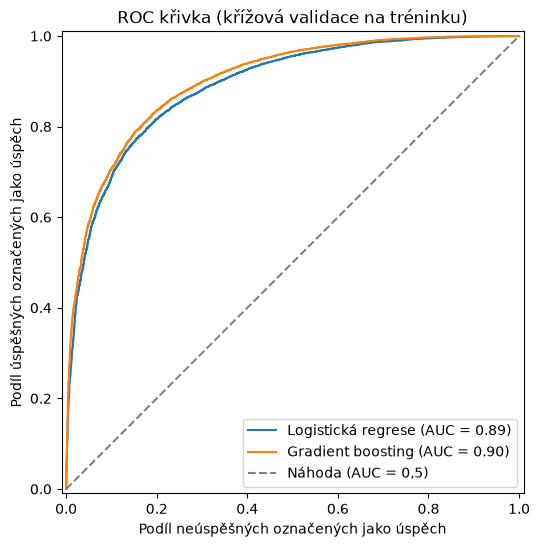

In [48]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_train, logreg_cv_proba, name="Logistická regrese", ax=ax)
RocCurveDisplay.from_predictions(y_train, boosting_cv_proba, name="Gradient boosting", ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Náhoda (AUC = 0,5)")
ax.set_title("ROC křivka (křížová validace na tréninku)")
ax.set_xlabel("Podíl neúspěšných označených jako úspěch")
ax.set_ylabel("Podíl úspěšných označených jako úspěch")
ax.legend(loc="lower right")
plt.show()

Model vrací pravděpodobnost úspěchu a kampaň označíme za úspěšnou, pokud tato pravděpodobnost překročí práh. Při prahu 0,5 model kvůli 70 % úspěšných kampaní předpovídá převážně „úspěch“ a značnou část neúspěšných kampaní nezachytí. Model si představujeme jako pomůcku pro tvůrce před spuštěním kampaně. Falešně pozitivní předpověď (model slíbí úspěch, kampaň selže) tvůrce stojí čas a peníze vložené do přípravy, falešně negativní předpověď (model odradí od kampaně, která by uspěla) znamená ušlou příležitost. Falešný příslib úspěchu považujeme pro tvůrce za závažnější chybu, protože vede k investici času a peněz do kampaně, která pravděpodobně selže. Chceme proto spolehlivě zachytit i menšinovou třídu neúspěšných kampaní. Při stejné ceně obou chyb by byl vhodnější práh blízký 0,5, který maximalizuje accuracy. Pro platformu nebo investora, kterému jde především o výběr kampaní s vysokou šancí na úspěch, by byl vhodnější vyšší práh. Práh proto volíme tak, aby byla co nejvyšší balanced accuracy, tedy průměr podílu zachycených úspěšných a zachycených neúspěšných kampaní (na ROC křivce odpovídá Youdenovu indexu).

Tabulka uvádí výsledky při prahu 0,5 i při zvoleném prahu, aby bylo zřejmé, co volbou získáme a co ztratíme.

In [49]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, roc_curve


def best_balanced_threshold(y_true, proba):
    """Práh s nejvyšší balanced accuracy (maximum TPR − FPR na ROC křivce)."""
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_true, proba)
    best = (true_positive_rate - false_positive_rate).argmax()
    return thresholds[best]


def threshold_summary(y_true, proba, threshold):
    """Metriky při zvoleném prahu."""
    predicted = (proba >= threshold).astype(int)
    return {
        "Práh": threshold,
        "Accuracy": accuracy_score(y_true, predicted),
        "Balanced accuracy": balanced_accuracy_score(y_true, predicted),
        "Zachycené úspěšné": recall_score(y_true, predicted, pos_label=1),
        "Zachycené neúspěšné": recall_score(y_true, predicted, pos_label=0),
    }

In [50]:
logreg_threshold = best_balanced_threshold(y_train, logreg_cv_proba)
boosting_threshold = best_balanced_threshold(y_train, boosting_cv_proba)

threshold_table = pd.DataFrame({
    "Logistická regrese · práh 0,5": threshold_summary(y_train, logreg_cv_proba, 0.5),
    "Logistická regrese · zvolený práh": threshold_summary(y_train, logreg_cv_proba, logreg_threshold),
    "Gradient boosting · práh 0,5": threshold_summary(y_train, boosting_cv_proba, 0.5),
    "Gradient boosting · zvolený práh": threshold_summary(y_train, boosting_cv_proba, boosting_threshold),
}).T.round(3)
display(threshold_table)

,Práh,Accuracy,Balanced accuracy,Zachycené úspěšné,Zachycené neúspěšné
"Logistická regrese · práh 0,5",0.500,0.809,0.808,0.811,0.806
Logistická regrese · zvolený práh,0.560,0.797,0.809,0.779,0.840
"Gradient boosting · práh 0,5",0.500,0.842,0.791,0.913,0.669
Gradient boosting · zvolený práh,0.683,0.823,0.819,0.828,0.809


Confusion matrix při zvoleném prahu ukazuje, kolik kampaní z každé třídy model zařadil správně a kolik chybně.

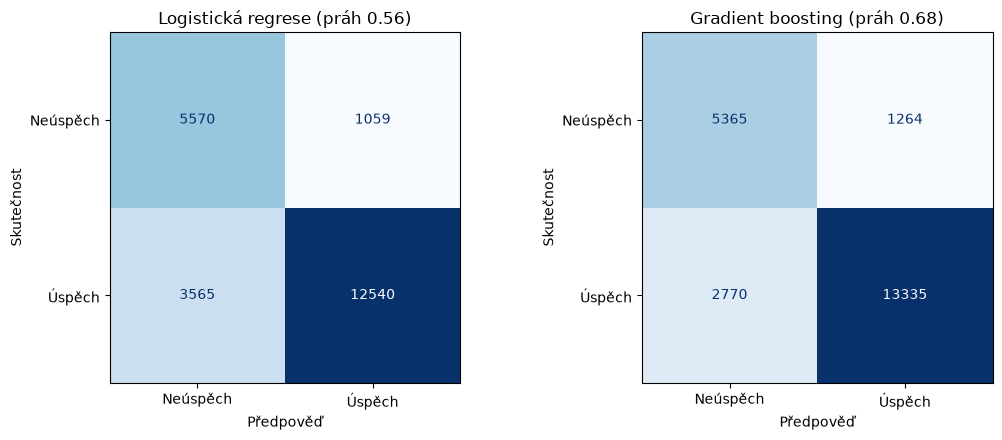

In [51]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name, proba, threshold in [
    (axes[0], "Logistická regrese", logreg_cv_proba, logreg_threshold),
    (axes[1], "Gradient boosting", boosting_cv_proba, boosting_threshold),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_train, (proba >= threshold).astype(int),
        display_labels=["Neúspěch", "Úspěch"], cmap="Blues", ax=ax, colorbar=False,
    )
    ax.set_title(f"{name} (práh {threshold:.2f})")
    ax.set_xlabel("Předpověď")
    ax.set_ylabel("Skutečnost")
plt.tight_layout()
plt.show()

Výsledky:
- ROC křivky obou modelů jsou si blízké, gradient boosting leží téměř v celém průběhu mírně nad logistickou regresí.
- Gradient boosting při prahu 0,5 zachytí 91 % úspěšných, ale pouze 67 % neúspěšných kampaní, předpovídá tedy „úspěch“ příliš často.
- Při zvoleném prahu 0,68 zachytí 83 % úspěšných a 81 % neúspěšných kampaní. Accuracy klesne z 0,84 na 0,82, balanced accuracy však vzroste z 0,79 na 0,82. Obě třídy jsou zachyceny vyrovnaněji, což odpovídá našemu cíli.
- U logistické regrese vyšel optimální práh 0,56, tedy blízko 0,5, protože model již při trénování používá vyvážené váhy tříd.
- Tyto prahy (0,68 a 0,56) jsou zvoleny pouze na základě trénovací sady a na testovací sadě je neměníme.

<a id="s5"></a>
## 5. LLM příznaky (varianty B a C)

V této sekci přidáváme příznaky, které jazykový model vytvořil z názvu a krátkého popisu kampaně. Porovnáváme tři varianty:
- A: pouze 11 základních příznaků ([sekce 4](#s4)),
- B: základní příznaky + 6 příznaků z dotazníku, který jsme navrhli sami (`manual`),
- C: základní příznaky + 7 příznaků z dotazníku, který navrhl jazykový model (`discovered`).

Zajímají nás dvě otázky: zda LLM příznaky přinášejí informaci nad rámec základních příznaků a zda je vhodnější dotazník navržený člověkem, nebo modelem. Předem jsme očekávali, že ruční dotazník bude úspěšnější, protože vychází z průzkumu dat a ze znalosti fungování crowdfundingu.

<a id="s5-1"></a>
### 5.1 Vznik LLM příznaků

Generování probíhá v samostatném notebooku [`02_llm_features.ipynb`](notebooks/02_llm_features.ipynb), protože trvá více než dvě hodiny a není důvod jej opakovat při každém spuštění. Zde pouze načítáme výsledné CSV soubory.

#### Model a nastavení

Používáme model `qwen3.6-35b` (Qwen 3.6, 35B) na školním LiteLLM endpointu s nastavením `temperature = 0`, odpovědí ve formátu JSON a vypnutým „přemýšlením“ modelu. Kampaně odesíláme po 20 v jednom dotazu, každá má v promptu pouze pořadové číslo, název a popis. Model nikdy nevidí výsledek kampaně: sloupec `state` slouží v notebooku 02 pouze k výběru dokončených kampaní a ihned poté jej odstraňujeme, vybraná částka ani počet podporovatelů do promptu nevstupují. Odpovědi mimo povolené hodnoty ukládáme jako chybějící a každou dávku ukládáme do cache.

#### Ruční dotazník (`manual`)

Dotazník jsme navrhli na základě průzkumu dat a úvahy, které vlastnosti lze z názvu a popisu rozpoznat na první pohled. Například u kategorie Food uspěje pouze 27 % kampaní a mezi názvy neúspěšných kampaní se často objevují žádosti o záchranu nebo otevření podniku, z čehož vycházejí příznaky `funding_purpose` a `appeal_type`.

#### Dotazník navržený modelem (`discovered`)

Model obdržel 169 názvů a popisů kampaní (leden–říjen, stratifikovaně podle kategorie, nejméně 5 z každé) bez informace o výsledku a měl navrhnout 6–10 příznaků. V zadání měl zakázáno opakovat kategorii projektu a využívat informace, které v textu nejsou (například vybranou částku nebo pověst tvůrce). Výsledný dotazník přesto obsahuje příznak `creator_credibility_signal`. Zákaz v promptu mířil na znalosti mimo text, příznak naopak hodnotí pouze to, co je v názvu nebo popisu výslovně uvedeno (ocenění, známá značka, předchozí díla). Po úpravě (viz níže) tuto podmínku jeho definice výslovně obsahuje.

Návrh jsme jednou mírně upravili. Rozhodovali jsme výhradně podle znění definic a ukázkových odpovědí z pilotu, souvislost příznaků s úspěchem jsme při tom nezkoumali:
- `urgency_or_scarcity` jsme vyřadili, protože jeho definice obsahovala výrazy jako „launch“ nebo „pre-order“, které odpovídají téměř každé kampani. Model jej přiřazoval například i termínům divadelních představení.
- Definici `creator_credibility_signal` jsme zpřesnili na výslovně uvedená ocenění nebo známé značky. V pilotu model hodnotil debutové album jako „zavedenou značku“ a vojenská vyznamenání jako „ocenění“.

Původní návrh je uložen v [`_data/ai/schema_discovered_v1_raw.json`](_data/ai/schema_discovered_v1_raw.json), upravená verze včetně zdůvodnění v [`_data/ai/schema_discovered.json`](_data/ai/schema_discovered.json).

#### Pilot

Oba dotazníky jsme nejprve vyzkoušeli na 309 jiných kampaních (leden–říjen). Žádná dávka neselhala a chybějící hodnoty byly téměř nulové. 60 kampaní jsme v rámci pilotu odeslali podruhé v jiném pořadí: binární příznaky a kategorie se shodovaly v 85–100 % případů, škály 1–5 přesně v 62–80 % a s tolerancí ±1 v 97–100 %. Srovnání pilotu s plným během v [5.2](#s5-2) však ukazuje, že u některých příznaků je stabilita nižší. Poté jsme oba dotazníky zafixovali a spustili plný běh na všech 26 635 dokončených kampaních.

Kampaně z discovery a pilotu (478) jsou i s jejich tvůrci vždy součástí trénovací sady ([3.5](#s3-5)). Výběr pouze z ledna až října je pozůstatkem původního plánu s testovací sadou z listopadu a prosince.

Přehled příznaků v obou dotaznících. Popisy pro model jsou v angličtině, protože většina textů je anglicky. Úplné definice jsou v souborech [`_data/ai/schema_used_manual.json`](_data/ai/schema_used_manual.json) a [`_data/ai/schema_used_discovered.json`](_data/ai/schema_used_discovered.json).

| Dotazník | Příznak | Význam |
| --- | --- | --- |
| manual | `funding_purpose` | Účel financování: produkt, tvůrčí dílo, provoz podniku, charita, akce, jiné. |
| manual | `has_concrete_deliverable` | Zda podporovatelé obdrží konkrétní věc, nebo jde pouze o podporu. |
| manual | `project_stage` | Fáze projektu: nápad, rozpracovaný, dokončený, nejasné. |
| manual | `appeal_type` | Nabídka podporovatelům, prosba o pomoc, nebo kombinace. |
| manual | `specificity` | Konkrétnost popisu, od 1 (slogan) do 5 (přesně co, jak a pro koho). |
| manual | `language` | Jazyk názvu a popisu. |
| discovered | `has_clear_value_proposition` | Zda popis jasně uvádí, jaký problém projekt řeší nebo jaký přínos má. |
| discovered | `has_tangible_reward` | Zda kampaň nabízí fyzický předmět nebo konkrétní digitální produkt. |
| discovered | `is_series_continuation` | Zda jde o pokračování, další díl nebo součást série. |
| discovered | `creator_credibility_signal` | Výslovně uvedené ocenění nebo bestseller, známá značka nebo tým, případně nic. |
| discovered | `social_or_political_appeal` | Zda kampaň staví na sociálním nebo politickém tématu, identitě nebo aktivismu. |
| discovered | `technical_complexity` | Technická náročnost, od 1 (ruční výroba, kniha) do 5 (patentovaná nebo velmi složitá technologie). |
| discovered | `has_emotional_hook` | Zda popis využívá výrazně emotivní jazyk nebo příběh. |

Aby bylo srovnání férové, prochází každá varianta stejným laděním jako varianta A: stejné foldy, stejné rozsahy hyperparametrů a stejný počet kombinací. Nejlepší hodnoty si však každá varianta hledá samostatně, protože s novými příznaky může být vhodné jiné nastavení. Kroky ze [sekce 4](#s4) proto spojujeme do jedné funkce, která používá tytéž proměnné (`logreg_search_space`, `boosting_search_space`, `cv`, `scoring`), takže se nic nepřepisuje ručně. Kontrola v [5.4](#s5-4) ověřuje, že funkce dává na variantě A shodné výsledky jako sekce 4.

In [52]:
def tune_both_models(X, numeric, binary, categorical):
    """Stejné ladění jako v sekci 4 (logistická regrese i gradient boosting) pro libovolnou sadu příznaků."""
    preprocessing = ColumnTransformer([
        ("numbers", Pipeline([
            ("fill_missing", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), numeric),
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("binary", SimpleImputer(strategy="most_frequent"), binary),
    ])
    logreg = Pipeline([
        ("preprocessing", preprocessing),
        ("model", LogisticRegression(max_iter=2000)),
    ])
    boosting = HistGradientBoostingClassifier(
        categorical_features="from_dtype", early_stopping=False, random_state=42,
    )

    searches = {}
    for name, model, space, iterations in [
        ("Logistická regrese", logreg, logreg_search_space, 20),
        ("Gradient boosting", boosting, boosting_search_space, 25),
    ]:
        search = RandomizedSearchCV(
            model, space, n_iter=iterations, scoring=scoring, refit="roc_auc",
            cv=cv, random_state=42, n_jobs=-1,
        )
        started = time.perf_counter()
        search.fit(X, y_train, groups=groups_train)
        print(f"{name}: ladění trvalo {time.perf_counter() - started:.0f} s.")
        searches[name] = search
    return searches

<a id="s5-2"></a>
### 5.2 Načtení LLM příznaků

Hotové příznaky připojujeme k trénovací i testovací sadě podle ID kampaně. Plný běh zpracoval všech 26 635 dokončených kampaní, příznaky má tedy každá kampaň v modelu.

Chybějících hodnot je minimum: 48 u jazyka (0,2 %) a 20 u `creator_credibility_signal` (0,08 %, jedna dávka, ve které model pole vynechal). Logistická regrese je doplňuje v pipeline, gradient boosting s nimi pracuje přímo.

In [53]:
llm_manual = pd.read_csv(ai_dir / "llm_features_manual.csv", dtype={"id": str}).set_index("id")
llm_discovered = pd.read_csv(ai_dir / "llm_features_discovered.csv", dtype={"id": str}).set_index("id")

print(f"Ruční schéma (manual): {len(llm_manual):,} kampaní, {llm_manual.shape[1]} příznaků")
print(f"Schéma od modelu (discovered): {len(llm_discovered):,} kampaní, {llm_discovered.shape[1]} příznaků")

# Každá kampaň z tréninku i testu musí mít LLM příznaky.
assert set(model_projects.index) <= set(llm_manual.index)
assert set(model_projects.index) <= set(llm_discovered.index)

display(pd.concat([llm_manual, llm_discovered], axis=1).isna().sum().rename("Chybí").to_frame())

Ruční schéma (manual): 26,635 kampaní, 6 příznaků
Schéma od modelu (discovered): 26,635 kampaní, 7 příznaků


,Chybí
llm_funding_purpose,0
llm_has_concrete_deliverable,0
llm_project_stage,0
llm_appeal_type,0
llm_specificity,0
llm_language,48
llm_has_clear_value_proposition,0
llm_has_tangible_reward,0
llm_is_series_continuation,0
llm_creator_credibility_signal,20


Všech 309 pilotních kampaní model zpracoval dvakrát, v pilotu a znovu v plném běhu, pokaždé v jiných dávkách. Tabulka ukazuje, jak často se obě odpovědi shodují.

In [54]:
stability_rows = []
for schema, full_run in [("manual", llm_manual), ("discovered", llm_discovered)]:
    pilot_run = pd.read_csv(ai_dir / f"pilot_features_{schema}.csv", dtype={"id": str}).set_index("id")
    common = pilot_run.index.intersection(full_run.index)
    for column in full_run.columns:
        pilot_values = pilot_run.loc[common, column]
        full_values = full_run.loc[common, column]
        row = {
            "Dotazník": schema,
            "Příznak": column.removeprefix("llm_"),
            "Přesná shoda": pilot_values.astype(str).eq(full_values.astype(str)).mean(),
        }
        if column in ("llm_specificity", "llm_technical_complexity"):
            row["Shoda ±1"] = (pilot_values - full_values).abs().le(1).mean()
        stability_rows.append(row)

print(f"Kampaní v obou bězích: {len(common)}")
display(pd.DataFrame(stability_rows).set_index(["Dotazník", "Příznak"]).round(3))

Kampaní v obou bězích: 309


Přesná shoda  Shoda ±1
Dotazník   Příznak                                            
manual     funding_purpose                     0.861       NaN
           has_concrete_deliverable            0.984       NaN
           project_stage                       0.751       NaN
           appeal_type                         0.948       NaN
           specificity                         0.670     1.000
           language                            0.994       NaN
discovered has_clear_value_proposition         0.773       NaN
           has_tangible_reward                 0.945       NaN
           is_series_continuation              0.964       NaN
           creator_credibility_signal          0.951       NaN
           social_or_political_appeal          0.984       NaN
           technical_complexity                0.812     0.997
           has_emotional_hook                  0.858       NaN

Mezi pilotem a plným během je shoda nižší než při opakování uvnitř pilotu. Nejméně stabilní jsou `project_stage` (75 %), `has_clear_value_proposition` (77 %) a přesná hodnota škály `specificity` (67 %, s tolerancí ±1 téměř vždy). Odpovědi tedy závisejí i na tom, s jakými kampaněmi je projekt v dávce. U těchto příznaků je proto model zatížen šumem a jejich důležitost v [6.5](#s6-5) je třeba vykládat opatrně.

Typy příznaků určujeme stejně jako v [4.1](#s4-1): binární hodnoty převádíme na 1/0, škály 1–5 (`specificity`, `technical_complexity`) považujeme za číselné, protože mají přirozené pořadí, a ostatní příznaky jsou kategorie se seznamem hodnot z trénovací sady.

In [55]:
manual_numeric = ["llm_specificity"]
manual_binary = ["llm_has_concrete_deliverable"]
manual_categorical = ["llm_funding_purpose", "llm_project_stage", "llm_appeal_type", "llm_language"]

discovered_numeric = ["llm_technical_complexity"]
discovered_binary = [
    "llm_has_clear_value_proposition", "llm_has_tangible_reward", "llm_is_series_continuation",
    "llm_social_or_political_appeal", "llm_has_emotional_hook",
]
discovered_categorical = ["llm_creator_credibility_signal"]

# Kontrola, že jsme žádný LLM příznak nevynechali.
assert sorted(manual_numeric + manual_binary + manual_categorical) == sorted(llm_manual.columns)
assert sorted(discovered_numeric + discovered_binary + discovered_categorical) == sorted(llm_discovered.columns)

In [56]:
# Varianta B = základní příznaky + ruční schéma, varianta C = základní příznaky + schéma od modelu.
X_train_b = X_train.join(llm_manual)
X_test_b = X_test.join(llm_manual)
X_train_c = X_train.join(llm_discovered)
X_test_c = X_test.join(llm_discovered)

for train_part, test_part, binary, categorical in [
    (X_train_b, X_test_b, manual_binary, manual_categorical),
    (X_train_c, X_test_c, discovered_binary, discovered_categorical),
]:
    for column in binary:
        train_part[column] = train_part[column].astype(int)
        test_part[column] = test_part[column].astype(int)
    for column in categorical:
        train_values = sorted(train_part[column].dropna().unique())
        train_part[column] = pd.Categorical(train_part[column], categories=train_values)
        test_part[column] = pd.Categorical(test_part[column], categories=train_values)

print(f"Varianta B: {X_train_b.shape[1]} příznaků · varianta C: {X_train_c.shape[1]} příznaků")
assert X_train_b.index.equals(X_train.index) and X_test_c.index.equals(X_test.index)

Varianta B: 17 příznaků · varianta C: 18 příznaků


<a id="s5-3"></a>
### 5.3 Úspěšnost podle hodnot LLM příznaků (pouze trénovací sada)

Před zařazením do modelu ověřujeme, jak se úspěšnost liší podle hodnot jednotlivých příznaků. Výrazný rozdíl však ještě neznamená přínos pro model, protože příznak může pouze opakovat informaci, kterou model získává z kategorie nebo cíle.

In [57]:
rows = []
for X_part, columns in [(X_train_b, llm_manual.columns), (X_train_c, llm_discovered.columns)]:
    for column in columns:
        summary = y_train.groupby(X_part[column], observed=True).agg(["size", "mean"])
        for value, row in summary.iterrows():
            rows.append({
                "Příznak": column.removeprefix("llm_"),
                "Hodnota": value,
                "Kampaní": int(row["size"]),
                "Úspěšnost": f"{row['mean']:.1%}",
            })

display(pd.DataFrame(rows).set_index(["Příznak", "Hodnota"]))

Kampaní Úspěšnost
Příznak                     Hodnota                                     
funding_purpose             business_operations           1390     19.6%
                            charity_or_cause               253     30.4%
                            creative_work                13276     76.3%
                            event                          322     50.9%
                            other                          228     27.2%
                            product                       7265     74.3%
has_concrete_deliverable    0                             1827     26.4%
                            1                            20907     74.7%
project_stage               finished                      2614     88.3%
                            idea                          2817     37.1%
                            in_progress                  16771     73.9%
                            unclear                        532     66.2%
appeal_type                 mixed                         1350     38.0%
                            offer_to_backers             20103     75.5%
                            personal_plea                 1281     33.1%
specificity                 1                              700     42.9%
                            2                             3394     54.6%
                            3                             9710     67.1%
                            4                             7859     81.8%
                            5                             1071     94.7%
language                    de                             131     38.9%
                            en                           22016     71.9%
                            es                             250     32.4%
                            fr                             139     45.3%
                            it                             100     35.0%
                            ja                              18     55.6%
                            nl                               7     42.9%
                            other                           22     54.5%
                            zh                              10     30.0%
has_clear_value_proposition 0                             7636     69.4%
                            1                            15098     71.6%
has_tangible_reward         0                             3577     40.2%
                            1                            19157     76.6%
is_series_continuation      0                            20227     68.3%
                            1                             2507     91.2%
creator_credibility_signal  awards_or_bestseller           245     85.7%
                            established_brand_or_team     1931     87.1%
                            none                         20542     69.1%
social_or_political_appeal  0                            20650     72.9%
                            1                             2084     50.2%
technical_complexity        1                            13337     72.0%
                            2                             4994     61.1%
                            3                             2821     84.7%
                            4                             1380     66.2%
                            5                              202     73.3%
has_emotional_hook          0                            10941     73.9%
                            1                            11793     68.0%

Výsledky:
- `specificity` roste plynule se stupnicí, z 43 % (1) na 95 % (5),
- `project_stage`: nápad 37 %, dokončený projekt 88 %,
- `is_series_continuation`: pokračování série 91 %, ostatní 68 %,
- `has_tangible_reward`: bez hmatatelné odměny 40 %, s odměnou 77 %,
- `language` (97 % angličtina) a `has_clear_value_proposition` (69 % oproti 72 %) téměř nerozlišují,
- `technical_complexity` se se stupnicí nemění monotónně a spíše kopíruje kategorii.

Značná část rozdílů pravděpodobně souvisí s kategorií a cílem, které model již zná, skutečný přínos proto ukáže až srovnání variant.

<a id="s5-4"></a>
### 5.4 Ladění variant B a C

Pro každou variantu použijeme stejnou funkci, LLM příznaky pouze přidáváme k seznamům sloupců ze [sekce 4](#s4).

In [58]:
searches_b = tune_both_models(
    X_train_b,
    numeric_columns + manual_numeric,
    binary_columns + manual_binary,
    categorical_columns + manual_categorical,
)

Logistická regrese: ladění trvalo 7 s.


Gradient boosting: ladění trvalo 29 s.


In [59]:
searches_c = tune_both_models(
    X_train_c,
    numeric_columns + discovered_numeric,
    binary_columns + discovered_binary,
    categorical_columns + discovered_categorical,
)

Logistická regrese: ladění trvalo 7 s.


Gradient boosting: ladění trvalo 31 s.


Kontrola: funkce `tune_both_models` musí na variantě A (bez LLM příznaků) dát stejné výsledky jako ladění v sekci 4.

In [60]:
check_a = tune_both_models(X_train, numeric_columns, binary_columns, categorical_columns)
for model_name, original_search in [("Logistická regrese", logreg_search), ("Gradient boosting", boosting_search)]:
    print(f"{model_name}: sekce 4 {original_search.best_score_:.4f}, funkce {check_a[model_name].best_score_:.4f}")
    assert np.isclose(original_search.best_score_, check_a[model_name].best_score_)

Logistická regrese: ladění trvalo 6 s.


Gradient boosting: ladění trvalo 25 s.
Logistická regrese: sekce 4 0.8902, funkce 0.8902
Gradient boosting: sekce 4 0.9014, funkce 0.9014


Nejlepší kombinace gradient boostingu pro varianty B a C:

In [61]:
display(top_results(searches_b["Gradient boosting"], count=3))
display(top_results(searches_c["Gradient boosting"], count=3))

,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,mean_test_roc_auc,std_test_roc_auc,mean_test_accuracy
22,0.0211,0.0124,506,38,312,0.9046,0.0030,0.8452
18,1.6173,0.0129,426,23,363,0.9043,0.0027,0.8443
15,0.0023,0.0195,289,54,232,0.9043,0.0022,0.8448


,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,mean_test_roc_auc,std_test_roc_auc,mean_test_accuracy
22,0.0211,0.0124,506,38,312,0.9061,0.0018,0.8453
6,7.8528,0.0221,545,61,465,0.9059,0.0023,0.8467
10,0.0084,0.0227,543,21,447,0.9057,0.0025,0.8440


<a id="s5-5"></a>
### 5.5 Srovnání variant A, B a C (křížová validace)

Pro každý model a variantu uvádíme nejlepší kombinaci hyperparametrů.

In [62]:
searches_a = {"Logistická regrese": logreg_search, "Gradient boosting": boosting_search}
variant_names = ["A: bez LLM", "B: ruční schéma", "C: schéma od modelu"]
all_searches = dict(zip(variant_names, [searches_a, searches_b, searches_c]))

rows = []
for model_name in ["Logistická regrese", "Gradient boosting"]:
    for variant in variant_names:
        rows.append({"Model": model_name, "Varianta": variant, **best_scores(all_searches[variant][model_name])})

comparison_abc = pd.DataFrame(rows).set_index(["Model", "Varianta"]).round(4)
display(comparison_abc)

ROC AUC (průměr)  ROC AUC (odchylka)  \
Model              Varianta                                                    
Logistická regrese A: bez LLM                     0.8902              0.0029   
                   B: ruční schéma                0.8956              0.0037   
                   C: schéma od modelu            0.8954              0.0030   
Gradient boosting  A: bez LLM                     0.9014              0.0024   
                   B: ruční schéma                0.9046              0.0030   
                   C: schéma od modelu            0.9061              0.0018   

                                        Accuracy (průměr)  
Model              Varianta                                
Logistická regrese A: bez LLM                      0.8094  
                   B: ruční schéma                 0.8143  
                   C: schéma od modelu             0.8132  
Gradient boosting  A: bez LLM                      0.8417  
                   B: ruční schéma                 0.8452  
                   C: schéma od modelu             0.8453

Všechny varianty používají stejné foldy, lze je tedy porovnat fold po foldu. Pokud je LLM varianta lepší ve všech pěti foldech, jde o silnější doklad než samotný rozdíl průměrů.

In [63]:
def fold_auc(search):
    """ROC AUC nejlepší kombinace v každém z pěti foldů."""
    best = search.best_index_
    return np.array([search.cv_results_[f"split{fold}_test_roc_auc"][best] for fold in range(cv.n_splits)])


rows = []
for model_name in ["Logistická regrese", "Gradient boosting"]:
    baseline_folds = fold_auc(all_searches["A: bez LLM"][model_name])
    for variant in variant_names[1:]:
        difference = fold_auc(all_searches[variant][model_name]) - baseline_folds
        rows.append({
            "Model": model_name,
            "Varianta": variant,
            "Rozdíl AUC proti A (průměr)": difference.mean(),
            "Nejmenší rozdíl ve foldu": difference.min(),
            "Největší rozdíl ve foldu": difference.max(),
            "Foldů, kde je lepší": f"{(difference > 0).sum()} z {cv.n_splits}",
        })

display(pd.DataFrame(rows).set_index(["Model", "Varianta"]).round(4))

Rozdíl AUC proti A (průměr)  \
Model              Varianta                                           
Logistická regrese B: ruční schéma                           0.0054   
                   C: schéma od modelu                       0.0052   
Gradient boosting  B: ruční schéma                           0.0032   
                   C: schéma od modelu                       0.0047   

                                        Nejmenší rozdíl ve foldu  \
Model              Varianta                                        
Logistická regrese B: ruční schéma                        0.0039   
                   C: schéma od modelu                    0.0043   
Gradient boosting  B: ruční schéma                        0.0021   
                   C: schéma od modelu                    0.0034   

                                        Největší rozdíl ve foldu  \
Model              Varianta                                        
Logistická regrese B: ruční schéma                        0.0068   
                   C: schéma od modelu                    0.0056   
Gradient boosting  B: ruční schéma                        0.0050   
                   C: schéma od modelu                    0.0059   

                                       Foldů, kde je lepší  
Model              Varianta                                 
Logistická regrese B: ruční schéma                   5 z 5  
                   C: schéma od modelu               5 z 5  
Gradient boosting  B: ruční schéma                   5 z 5  
                   C: schéma od modelu               5 z 5

Výsledky:
- Obě LLM varianty zlepšují oba modely, a to ve všech pěti foldech. Logistické regresi přidávají přibližně 0,005 AUC, gradient boostingu 0,003 (B) a 0,005 (C).
- Zlepšení je malé, ale konzistentní: i nejmenší rozdíl ve foldu je kladný a převyšuje rozdíly mezi nejlepšími kombinacemi hyperparametrů.
- Ruční dotazník a dotazník navržený modelem dosahují prakticky shodných výsledků. U logistické regrese 0,8956 oproti 0,8954, u gradient boostingu má varianta C náskok 0,0015, což je méně než směrodatná odchylka mezi foldy. Naše očekávání, že ruční dotazník bude lepší, se nepotvrdilo.
- Logistická regrese získává o něco více než gradient boosting. Pravděpodobně proto, že gradient boosting část stejné informace odvodí sám z kombinací základních příznaků.
- Nejlepší kombinace hyperparametrů je u variant B i C stejná, jaká byla druhá nejlepší u varianty A, ladění tedy srovnání nezkresluje.

<a id="s6"></a>
## 6. Vyhodnocení na testovací sadě

Testovací sadu nyní používáme poprvé a pouze jednou, pro všech šest předem určených modelů (2 modely × 3 varianty). Na testovací sadě nic nevybíráme ani neladíme, hyperparametry i prahy pocházejí z trénovací sady.

<a id="s6-1"></a>
### 6.1 Prahy pro varianty B a C

Prahy pro varianty B a C volíme stejně jako v [4.7](#s4-7), tedy z out-of-fold předpovědí na trénovací sadě podle nejvyšší balanced accuracy. Pro variantu A použijeme předpovědi z [4.7](#s4-7).

In [64]:
train_sets = dict(zip(variant_names, [X_train, X_train_b, X_train_c]))
test_sets = dict(zip(variant_names, [X_test, X_test_b, X_test_c]))

cv_proba = {
    ("A: bez LLM", "Logistická regrese"): logreg_cv_proba,
    ("A: bez LLM", "Gradient boosting"): boosting_cv_proba,
}
for variant in variant_names[1:]:
    for model_name, search in all_searches[variant].items():
        cv_proba[(variant, model_name)] = cross_val_predict(
            search.best_estimator_, train_sets[variant], y_train,
            groups=groups_train, cv=cv, method="predict_proba", n_jobs=-1,
        )[:, 1]

thresholds = {key: best_balanced_threshold(y_train, proba) for key, proba in cv_proba.items()}
display(pd.Series(thresholds, name="Zvolený práh").round(3).to_frame())

Zvolený práh
A: bez LLM          Logistická regrese         0.560
                    Gradient boosting          0.683
B: ruční schéma     Logistická regrese         0.538
                    Gradient boosting          0.700
C: schéma od modelu Logistická regrese         0.551
                    Gradient boosting          0.712

<a id="s6-2"></a>
### 6.2 Výsledky na testovací sadě

`RandomizedSearchCV` po ladění znovu natrénoval nejlepší kombinaci na celé trénovací sadě a tyto modely nyní poprvé vyhodnocujeme na testovací sadě. ROC AUC nezávisí na prahu, accuracy uvádíme při prahu 0,5 i při zvoleném prahu, balanced accuracy a podíly zachycených úspěšných a neúspěšných kampaní při zvoleném prahu.

In [65]:
from sklearn.metrics import roc_auc_score

test_proba = {}
rows = []
for model_name in ["Logistická regrese", "Gradient boosting"]:
    for variant in variant_names:
        search = all_searches[variant][model_name]
        proba = search.best_estimator_.predict_proba(test_sets[variant])[:, 1]
        test_proba[(variant, model_name)] = proba

        at_threshold = threshold_summary(y_test, proba, thresholds[(variant, model_name)])
        rows.append({
            "Model": model_name,
            "Varianta": variant,
            "ROC AUC": roc_auc_score(y_test, proba),
            "Accuracy (práh 0,5)": accuracy_score(y_test, (proba >= 0.5).astype(int)),
            "Práh": at_threshold["Práh"],
            "Accuracy (zvolený práh)": at_threshold["Accuracy"],
            "Balanced accuracy": at_threshold["Balanced accuracy"],
            "Zachycené úspěšné": at_threshold["Zachycené úspěšné"],
            "Zachycené neúspěšné": at_threshold["Zachycené neúspěšné"],
        })

test_results = pd.DataFrame(rows).set_index(["Model", "Varianta"]).round(3)
print(f"Referenční model (vždy „úspěch“) na testu: ROC AUC 0,500 · accuracy {y_test.mean():.3f}")
display(test_results)

Referenční model (vždy „úspěch“) na testu: ROC AUC 0,500 · accuracy 0.699


ROC AUC  Accuracy (práh 0,5)   Práh  \
Model              Varianta                                                   
Logistická regrese A: bez LLM             0.880                0.799  0.560   
                   B: ruční schéma        0.885                0.804  0.538   
                   C: schéma od modelu    0.883                0.800  0.551   
Gradient boosting  A: bez LLM             0.892                0.834  0.683   
                   B: ruční schéma        0.894                0.835  0.700   
                   C: schéma od modelu    0.895                0.835  0.712   

                                        Accuracy (zvolený práh)  \
Model              Varianta                                       
Logistická regrese A: bez LLM                             0.780   
                   B: ruční schéma                        0.793   
                   C: schéma od modelu                    0.788   
Gradient boosting  A: bez LLM                             0.811   
                   B: ruční schéma                        0.806   
                   C: schéma od modelu                    0.803   

                                        Balanced accuracy  Zachycené úspěšné  \
Model              Varianta                                                    
Logistická regrese A: bez LLM                       0.795              0.757   
                   B: ruční schéma                  0.804              0.777   
                   C: schéma od modelu              0.802              0.767   
Gradient boosting  A: bez LLM                       0.807              0.817   
                   B: ruční schéma                  0.807              0.804   
                   C: schéma od modelu              0.806              0.799   

                                        Zachycené neúspěšné  
Model              Varianta                                  
Logistická regrese A: bez LLM                         0.834  
                   B: ruční schéma                    0.831  
                   C: schéma od modelu                0.836  
Gradient boosting  A: bez LLM                         0.797  
                   B: ruční schéma                    0.810  
                   C: schéma od modelu                0.813

Výsledky:
- Testovací sada potvrzuje výsledky křížové validace. Pořadí variant je stejné a AUC je přibližně o 0,01 nižší (gradient boosting A 0,892 oproti 0,901 v křížové validaci). Výběr hyperparametrů na stejných foldech vysvětluje jen malou část rozdílu, protože nejlepší kombinace se liší pouze v tisícinách AUC. Testovací sada má navíc mírně jiné složení: obsahuje více kampaní tvůrců s jedinou kampaní, které se předpovídají hůře ([6.7](#s6-7)), a méně kampaní tvůrců se čtyřmi a více kampaněmi (viz tabulka níže). Částečně je to dáno tím, že tvůrce kampaní použitých při návrhu AI části jsme celé zařadili do trénovací sady ([3.5](#s3-5)). Složení však pravděpodobně vysvětluje jen část rozdílu a zbytek může být dán náhodou, protože tvůrců s více kampaněmi je v testovací sadě málo. Rozdíl tedy jednoznačně vysvětlit nedokážeme, vzhledem k jeho velikosti (0,01 AUC) jej však nepovažujeme za známku výrazného přeučení.
- Nejlepší je gradient boosting, LLM varianty zlepšují AUC o 0,002–0,005 u obou modelů.
- Zlepšení AUC se v metrikách závislých na prahu téměř neprojeví, accuracy i balanced accuracy se mění nejvýše o 0,01. Prahy z trénovací sady posouvají u LLM variant rovnováhu mírně ve prospěch neúspěšných kampaní.

In [66]:
campaigns_per_group = groups.map(groups.value_counts())
composition = pd.DataFrame({
    "Tvůrci s jedinou kampaní": [campaigns_per_group[train_mask].eq(1).mean(), campaigns_per_group[test_mask].eq(1).mean()],
    "Tvůrci se 4 a více kampaněmi": [campaigns_per_group[train_mask].ge(4).mean(), campaigns_per_group[test_mask].ge(4).mean()],
}, index=["Trénovací sada", "Testovací sada"]).round(3)
display(composition)

,Tvůrci s jedinou kampaní,Tvůrci se 4 a více kampaněmi
Trénovací sada,0.709,0.127
Testovací sada,0.737,0.102


<a id="s6-3"></a>
### 6.3 Je rozdíl mezi variantami průkazný?

Testovací sada obsahuje necelé 4 000 kampaní, i její AUC je proto zatížena náhodnou chybou. Její velikost odhadujeme bootstrapem: 1 000× náhodně vybereme kampaně z testovací sady s opakováním a pokaždé spočítáme rozdíl AUC mezi LLM variantou a variantou A na stejném výběru. Prostředních 95 % rozdílů tvoří interval. Pokud interval neobsahuje nulu, rozdíl pravděpodobně není náhodný.

Výběr provádíme po jednotlivých kampaních. Tvůrců s více kampaněmi je v testovací sadě málo, výběr po tvůrcích by proto interval změnil jen mírně.

In [67]:
bootstrap_rng = np.random.default_rng(42)
y_test_values = y_test.to_numpy()
samples = [bootstrap_rng.integers(0, len(y_test_values), len(y_test_values)) for _ in range(1000)]

rows = []
for model_name in ["Logistická regrese", "Gradient boosting"]:
    baseline = test_proba[("A: bez LLM", model_name)]
    for variant in variant_names[1:]:
        with_llm = test_proba[(variant, model_name)]
        differences = [
            roc_auc_score(y_test_values[sample], with_llm[sample])
            - roc_auc_score(y_test_values[sample], baseline[sample])
            for sample in samples
        ]
        low, high = np.percentile(differences, [2.5, 97.5])
        rows.append({
            "Model": model_name,
            "Varianta": variant,
            "Rozdíl AUC proti A": roc_auc_score(y_test, with_llm) - roc_auc_score(y_test, baseline),
            "95% interval od": low,
            "95% interval do": high,
        })

display(pd.DataFrame(rows).set_index(["Model", "Varianta"]).round(4))

Rozdíl AUC proti A  95% interval od  \
Model              Varianta                                                   
Logistická regrese B: ruční schéma                  0.0053           0.0026   
                   C: schéma od modelu              0.0035           0.0006   
Gradient boosting  B: ruční schéma                  0.0030           0.0004   
                   C: schéma od modelu              0.0031           0.0005   

                                        95% interval do  
Model              Varianta                              
Logistická regrese B: ruční schéma               0.0081  
                   C: schéma od modelu           0.0062  
Gradient boosting  B: ruční schéma               0.0056  
                   C: schéma od modelu           0.0056

Všechny čtyři intervaly leží nad nulou, zlepšení díky LLM příznakům tedy platí i na testovací sadě. Je však malé: přibližně 0,003 AUC u gradient boostingu a 0,004–0,005 u logistické regrese. Intervaly variant B a C se překrývají, rozdíl mezi dotazníky tedy neprokazujeme.

<a id="s6-4"></a>
### 6.4 ROC křivky a confusion matrix na testovací sadě

Zobrazujeme pouze gradient boosting, který byl nejlepší ve všech variantách.

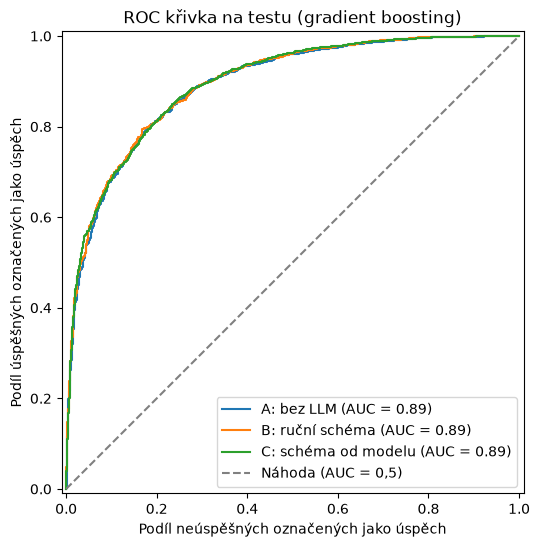

In [68]:
fig, ax = plt.subplots(figsize=(6, 6))
for variant in variant_names:
    RocCurveDisplay.from_predictions(
        y_test, test_proba[(variant, "Gradient boosting")], name=variant, ax=ax,
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Náhoda (AUC = 0,5)")
ax.set_title("ROC křivka na testu (gradient boosting)")
ax.set_xlabel("Podíl neúspěšných označených jako úspěch")
ax.set_ylabel("Podíl úspěšných označených jako úspěch")
ax.legend(loc="lower right")
plt.show()

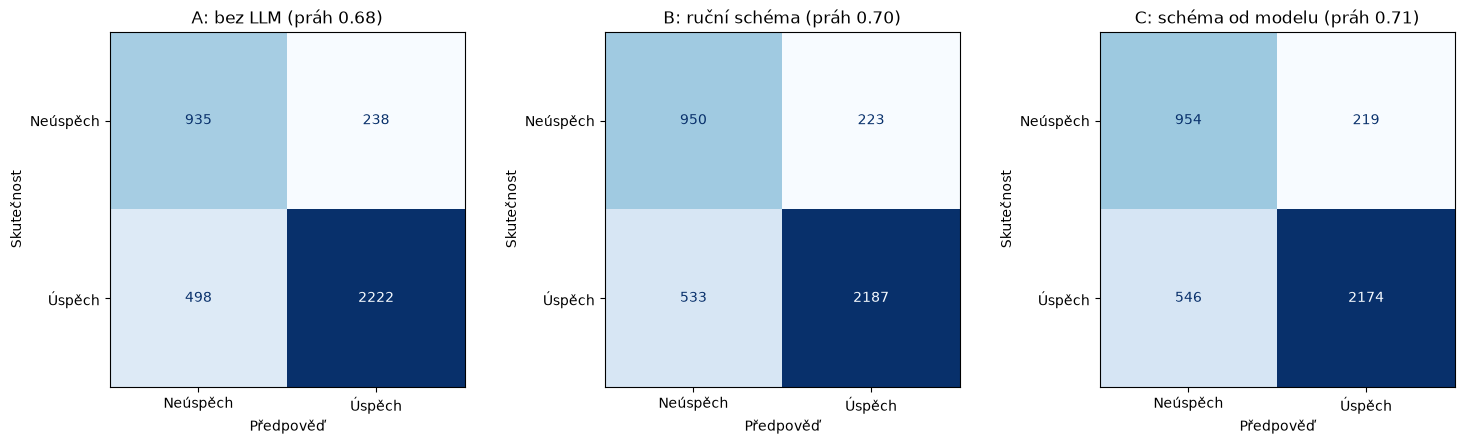

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, variant in zip(axes, variant_names):
    threshold = thresholds[(variant, "Gradient boosting")]
    predicted = (test_proba[(variant, "Gradient boosting")] >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted,
        display_labels=["Neúspěch", "Úspěch"], cmap="Blues", ax=ax, colorbar=False,
    )
    ax.set_title(f"{variant} (práh {threshold:.2f})")
    ax.set_xlabel("Předpověď")
    ax.set_ylabel("Skutečnost")
plt.tight_layout()
plt.show()

ROC křivky všech tří variant se téměř překrývají, rozdíl 0,003 AUC v grafu není patrný.

V confusion matrix varianta C oproti variantě A správně rozpozná o 19 neúspěšných kampaní více (954 oproti 935), ale o 48 úspěšných méně (2 174 oproti 2 222). Příčinou je především vyšší práh (0,71 oproti 0,68). Proto má varianta C při zvoleném prahu mírně nižší accuracy.

<a id="s6-5"></a>
### 6.5 Důležitost příznaků (permutation importance)

U každého příznaku na testovací sadě náhodně promícháme hodnoty a změříme, o kolik klesne ROC AUC. Čím větší je pokles, tím více model příznak využívá. Promíchání opakujeme pětkrát a uvádíme průměr.

Hodnotíme gradient boosting ve variantách B a C, abychom zjistili, které LLM příznaky model skutečně využil (v grafu oranžově).

Při interpretaci je třeba zohlednit, že pokud spolu dva příznaky souvisí (např. `technical_complexity` a kategorie), model po promíchání jednoho z nich využije část informace z druhého. Důležitost takových příznaků pak vychází nižší, než odpovídá jejich skutečné informační hodnotě.

In [70]:
from sklearn.inspection import permutation_importance

importances = {}
for variant in variant_names[1:]:
    result = permutation_importance(
        all_searches[variant]["Gradient boosting"].best_estimator_,
        test_sets[variant], y_test,
        scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1,
    )
    importances[variant] = pd.Series(result.importances_mean, index=test_sets[variant].columns).sort_values()

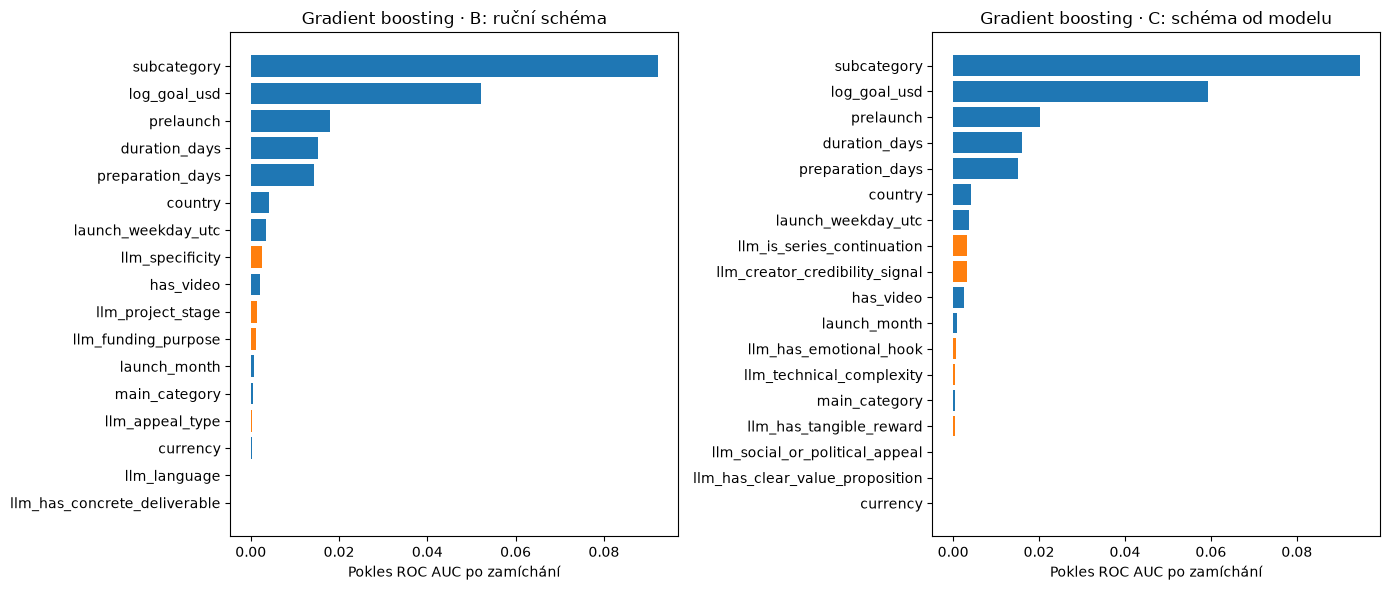

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (variant, importance) in zip(axes, importances.items()):
    colors = ["tab:orange" if name.startswith("llm_") else "tab:blue" for name in importance.index]
    ax.barh(importance.index, importance.values, color=colors)
    ax.set_title(f"Gradient boosting · {variant}")
    ax.set_xlabel("Pokles ROC AUC po zamíchání")
plt.tight_layout()
plt.show()

Výsledky:
- Model se opírá především o základní příznaky: podkategorii (pokles AUC přibližně 0,09), cíl (0,05–0,06), prelaunch, délku a dobu přípravy.
- Z ručního dotazníku přispívá nejvíce `specificity` (přibližně 0,003), méně `project_stage` a `funding_purpose`. Příznaky `has_concrete_deliverable` a `language` mají téměř nulovou důležitost: jazyk je téměř konstantní a informaci o konkrétní odměně pravděpodobně nesou i ostatní příznaky.
- Z dotazníku navrženého modelem přispívají nejvíce `is_series_continuation` a `creator_credibility_signal` (každý přibližně 0,003). Oba popisují zkušenost tvůrce nebo známou značku, tedy informaci, kterou základní příznaky neobsahují ([2.9](#s2-9)). Ostatní LLM příznaky mají téměř nulovou důležitost.
- Nízká důležitost neznamená, že je příznak bezcenný. LLM příznaky souvisí navzájem i s kategorií, při promíchání se proto mohou vzájemně zastoupit.

<a id="s6-6"></a>
### 6.6 Náklady AI části

Údaje pocházejí z plného běhu [`02_llm_features.ipynb`](notebooks/02_llm_features.ipynb) (`run_stats_full.csv`). Model běží na školním serveru s nulovou cenou za token, finanční náklady tedy byly nulové. Discovery a pilot představují jen malý zlomek (pilot 2 × 16 dotazů na 309 kampaní).

„Skutečný čas“ je doba běhu se čtyřmi souběžnými dotazy, „součet času dotazů“ odpovídá době, kterou by běh trval při postupném odesílání jednotlivých dotazů.

In [72]:
run_stats = pd.read_csv(ai_dir / "run_stats_full.csv").set_index("schema")
costs = pd.DataFrame({
    "Kampaní": run_stats["rows"],
    "Dotazů": run_stats["requests"],
    "Selhaných dávek": run_stats["failed_batches"],
    "Vstupní tokeny (mil.)": run_stats["prompt_tokens"] / 1e6,
    "Výstupní tokeny (mil.)": run_stats["completion_tokens"] / 1e6,
    "Skutečný čas (h)": run_stats["wall_seconds_this_run"] / 3600,
    "Součet času dotazů (h)": run_stats["api_seconds"] / 3600,
})
costs.loc["Celkem"] = costs.sum()
costs.loc["Celkem", "Kampaní"] = run_stats["rows"].max()  # obě schémata zpracovala stejné kampaně
display(costs.round(2))

,Kampaní,Dotazů,Selhaných dávek,Vstupní tokeny (mil.),Výstupní tokeny (mil.),Skutečný čas (h),Součet času dotazů (h)
schema,,,,,,,
manual,26635,1332,0,2.05,2.09,1.01,4.02
discovered,26635,1332,0,2.67,2.38,1.25,4.98
Celkem,26635,2664,0,4.72,4.47,2.25,9.00


<a id="s6-7"></a>
### 6.7 Časová kontrola (pouze trénovací sada)

Trénovací a testovací sadu dělíme náhodně podle tvůrců bez ohledu na datum spuštění. Trénovací sada proto obsahuje i kampaně spuštěné později než některé testovací a model může při trénování „nahlédnout do budoucnosti“. Pokud by se trh během roku měnil, výsledek na testovací sadě by byl nadhodnocený.

Tento vliv ověřujeme pouze na trénovací sadě. Rozdělíme ji podle data spuštění na minulost (leden–září) a budoucnost (říjen–prosinec), z budoucnosti vyřadíme kampaně tvůrců, kteří mají kampaň i v minulosti, a kopie modelů s nejlepšími hyperparametry natrénujeme pouze na minulosti. Pro srovnání vybereme pětkrát náhodně podle tvůrců stejně velkou část trénovací sady. Modely ze sekcí 4–6 zůstávají beze změny.

Kontrola má dvě omezení: hyperparametry byly laděny na celé trénovací sadě (to však platí pro obě rozdělení stejně) a model natrénovaný na lednu až září nezná měsíce 10–12, které však s výsledkem téměř nesouvisí ([3.9](#s3-9)).

In [73]:
train_launch_month = model_projects.loc[X_train.index, "launch_month"]
past_mask = train_launch_month <= 9
past_creators = set(groups_train[past_mask])
future_mask = ~past_mask & ~groups_train.isin(past_creators)

# Tvůrci, kteří mají v tréninku jen jednu kampaň. Budeme je potřebovat pro férové srovnání.
campaigns_per_creator = groups_train.map(groups_train.value_counts())
single_campaign = campaigns_per_creator.eq(1)

time_split_summary = pd.DataFrame({
    "Kampaní": [past_mask.sum(), (~past_mask).sum(), future_mask.sum(), len(y_train)],
    "Podíl úspěšných": [y_train[past_mask].mean(), y_train[~past_mask].mean(), y_train[future_mask].mean(), y_train.mean()],
    "Podíl tvůrců s jednou kampaní": [
        single_campaign[past_mask].mean(), single_campaign[~past_mask].mean(),
        single_campaign[future_mask].mean(), single_campaign.mean(),
    ],
}, index=[
    "Minulost: leden–září",
    "Říjen–prosinec celkem",
    "Budoucnost: říjen–prosinec bez tvůrců z minulosti",
    "Celý trénink",
]).round(3)
display(time_split_summary)

,Kampaní,Podíl úspěšných,Podíl tvůrců s jednou kampaní
Minulost: leden–září,17209,0.708,0.707
Říjen–prosinec celkem,5525,0.710,0.713
Budoucnost: říjen–prosinec bez tvůrců z minulosti,4036,0.625,0.975
Celý trénink,22734,0.708,0.709


Po vyřazení tvůrců z minulosti zůstávají v budoucnosti téměř výhradně tvůrci s jedinou kampaní (97,5 % oproti 71 % v celé trénovací sadě). Ti uspívají méně často (přibližně 63 % oproti 91 % u opakovaných tvůrců, [2.9](#s2-9)) a jejich kampaně se předpovídají obtížněji. U náhodného rozdělení proto počítáme AUC také pouze na kampaních tvůrců s jedinou kampaní, aby bylo srovnání férové.

In [74]:
from sklearn.base import clone


def random_creator_split(seed):
    """Náhodné rozdělení tréninku podle tvůrců. Učicí část má stejně kampaní jako minulost."""
    shuffled_groups = np.random.default_rng(seed).permutation(groups_train.unique())
    group_sizes = groups_train.value_counts().reindex(shuffled_groups)
    fit_groups = set(group_sizes.index[group_sizes.cumsum() <= past_mask.sum()])
    fit_mask = groups_train.isin(fit_groups)
    return fit_mask, ~fit_mask


def fit_part(model, X, fit_mask):
    """Naučí kopii modelu jen na vybrané části tréninku. Původní model zůstane beze změny."""
    return clone(model).fit(X.loc[fit_mask], y_train[fit_mask])


def auc_on(fitted, X, check_mask):
    """ROC AUC naučeného modelu na vybrané části tréninku."""
    return roc_auc_score(y_train[check_mask], fitted.predict_proba(X.loc[check_mask])[:, 1])


random_splits = [random_creator_split(seed) for seed in range(5)]

In [75]:
started = time.perf_counter()
rows = []
for model_name in ["Logistická regrese", "Gradient boosting"]:
    for variant in variant_names:
        model = all_searches[variant][model_name].best_estimator_
        X_variant = train_sets[variant]
        time_auc = auc_on(fit_part(model, X_variant, past_mask), X_variant, future_mask)
        random_all = []
        random_single = []
        for fit_mask, check_mask in random_splits:
            fitted = fit_part(model, X_variant, fit_mask)
            random_all.append(auc_on(fitted, X_variant, check_mask))
            random_single.append(auc_on(fitted, X_variant, check_mask & single_campaign))
        rows.append({
            "Model": model_name,
            "Varianta": variant,
            "Časové: budoucnost": time_auc,
            "Náhodné: všechny kampaně": np.mean(random_all),
            "Náhodné: tvůrci s jednou kampaní": np.mean(random_single),
            "Náhodné (jedna kampaň): nejmenší z 5": np.min(random_single),
            "Rozdíl při stejném složení": time_auc - np.mean(random_single),
        })

time_check = pd.DataFrame(rows).set_index(["Model", "Varianta"]).round(4)
print(f"Časová kontrola trvala {time.perf_counter() - started:.0f} s.")
display(time_check)

Časová kontrola trvala 65 s.


Časové: budoucnost  \
Model              Varianta                                  
Logistická regrese A: bez LLM                       0.8459   
                   B: ruční schéma                  0.8507   
                   C: schéma od modelu              0.8506   
Gradient boosting  A: bez LLM                       0.8578   
                   B: ruční schéma                  0.8623   
                   C: schéma od modelu              0.8646   

                                        Náhodné: všechny kampaně  \
Model              Varianta                                        
Logistická regrese A: bez LLM                             0.8877   
                   B: ruční schéma                        0.8937   
                   C: schéma od modelu                    0.8935   
Gradient boosting  A: bez LLM                             0.8988   
                   B: ruční schéma                        0.9031   
                   C: schéma od modelu                    0.9044   

                                        Náhodné: tvůrci s jednou kampaní  \
Model              Varianta                                                
Logistická regrese A: bez LLM                                     0.8594   
                   B: ruční schéma                                0.8662   
                   C: schéma od modelu                            0.8646   
Gradient boosting  A: bez LLM                                     0.8717   
                   B: ruční schéma                                0.8771   
                   C: schéma od modelu                            0.8780   

                                        Náhodné (jedna kampaň): nejmenší z 5  \
Model              Varianta                                                    
Logistická regrese A: bez LLM                                         0.8462   
                   B: ruční schéma                                    0.8545   
                   C: schéma od modelu                                0.8533   
Gradient boosting  A: bez LLM                                         0.8596   
                   B: ruční schéma                                    0.8658   
                   C: schéma od modelu                                0.8666   

                                        Rozdíl při stejném složení  
Model              Varianta                                         
Logistická regrese A: bez LLM                              -0.0135  
                   B: ruční schéma                         -0.0154  
                   C: schéma od modelu                     -0.0140  
Gradient boosting  A: bez LLM                              -0.0139  
                   B: ruční schéma                         -0.0148  
                   C: schéma od modelu                     -0.0134

Výsledky:
- Bez ohledu na složení kampaní je pokles výrazný (AUC 0,86 oproti 0,90), většina rozdílu je však způsobena tím, že v budoucnosti zůstali téměř výhradně tvůrci s jedinou kampaní.
- Při stejném složení je časové rozdělení horší přibližně o 0,014 AUC, tedy těsně pod nejhorším z pěti náhodných rozdělení. Časový efekt existuje, je však malý. Na skutečně budoucích kampaních by model dosáhl AUC přibližně o 0,01 nižší, než ukazuje testovací sada.
- Přínos LLM příznaků se potvrzuje i zde: gradient boosting A 0,858 → C 0,865, logistická regrese A 0,846 → B 0,851.
- U tvůrců s jedinou kampaní dosahuje model AUC přibližně 0,87, celkově 0,90. U nových tvůrců, pro které by byla předpověď nejužitečnější, je tedy model slabší.

<a id="s7"></a>
## 7. Závěr

Úspěch kampaně na Kickstarteru lze z údajů dostupných při spuštění předpovědět s poměrně dobrou přesností. Nejlepší model (gradient boosting) dosahuje na testovací sadě ROC AUC přibližně 0,89. Při zvoleném prahu správně zařadí přibližně 80 % úspěšných i neúspěšných kampaní (balanced accuracy 0,81, accuracy 0,80), při prahu 0,5 dosahuje accuracy 0,83. Referenční model dosahuje accuracy 0,70. Nejvýznamnějšími příznaky jsou podkategorie, výše cíle, prelaunch stránka, délka kampaně a doba přípravy.

#### Přínos LLM příznaků

LLM příznaky z názvu a popisu přinášejí dodatečnou, avšak malou informaci. Zlepšení AUC se projevilo ve všech provedených srovnáních: ve všech pěti foldech, u obou modelů i obou dotazníků, v bootstrapu na testovací sadě i v časové kontrole. Na testovací sadě se AUC gradient boostingu zlepšilo z 0,892 na 0,895 a logistické regrese z 0,880 na 0,885. U metrik závislých na prahu se však zlepšení neprojevilo: balanced accuracy gradient boostingu na testovací sadě zůstává 0,807 a accuracy při zvoleném prahu dokonce mírně klesá (0,811 → 0,803). Většinu informace obsažené v textu (o jaký projekt jde a jak je rozsáhlý) model získává již z kategorie a cíle. Text přidává především informaci, která jinde chybí: jak konkrétně je projekt popsán a zda za ním stojí zkušený tvůrce nebo známá značka.

Z praktického hlediska je přínos vzhledem k nákladům sporný. Zlepšení výsledného modelu (varianta C) o 0,003 AUC vyžadovalo 1 332 dotazů, přibližně 5 milionů tokenů a 1,25 hodiny běhu se čtyřmi souběžnými dotazy a na zvoleném pracovním bodě modelu se neprojevilo. Na bezplatném školním endpointu mělo smysl přístup vyzkoušet, při nasazení s placeným modelem bychom jej však bez dalšího zlepšení nedoporučili.

#### Ruční dotazník a dotazník navržený modelem

Rozdíl mezi dotazníky jsme neprokázali, obě varianty dosahují prakticky shodných výsledků. Naše očekávání, že ruční dotazník bude lepší, se tedy nepotvrdilo. Každý z dotazníků však zachytil jiný typ informace: ruční především konkrétnost a fázi projektu (`specificity`, `project_stage`), dotazník modelu především zkušenost tvůrce (`is_series_continuation`, `creator_credibility_signal`).

#### Výsledný model

Výsledným modelem je gradient boosting s příznaky z dotazníku navrženého modelem (varianta C), vybraný podle nejvyšší AUC v křížové validaci. Na testovací sadě dosahuje ROC AUC 0,895. Při zvoleném prahu 0,71 má balanced accuracy 0,806 a accuracy 0,803 (zachytí 80 % úspěšných a 81 % neúspěšných kampaní), při prahu 0,5 accuracy 0,835. Podle časové kontroly ([6.7](#s6-7)) lze u budoucích kampaní očekávat AUC přibližně 0,88 a u nových tvůrců s jedinou kampaní je model slabší než u zavedených tvůrců.

#### Limitace

- Model Qwen mohl některé kampaně z roku 2025 vidět během svého trénování.
- Název, popis, video i prelaunch pocházejí z posledního snapshotu, tvůrce je mohl po spuštění změnit. Ze snapshotů nelze ověřit, že tyto údaje odpovídají stavu při spuštění kampaně, a předpokládáme to. Pokud tvůrce text upravil až po skončení kampaně, mohly LLM příznaky nepřímo převzít i informaci o jejím výsledku.
- Odpovědi jazykového modelu nejsou zcela stabilní a závisejí i na ostatních kampaních v dávce. Mezi pilotem a plným během se u `project_stage` shodují jen v 75 % případů a přesná hodnota `specificity` v 67 % ([5.2](#s5-2)).
- Dotazník navržený modelem jsme mírně ručně upravili. Úpravy proběhly bez znalosti výsledků kampaní, jde však o zásah člověka.
- Ruční dotazník vychází z průzkumu dat, který zahrnoval i kampaně z testovací sady ([3.5](#s3-5)).
- Projekty ve stavu `live` z pozdějších snapshotů zmizely a jejich vyřazení není náhodné ([1.4](#s1-4)). Vyřazené jsou také zrušené kampaně (4 %), které by pravděpodobně většinou cíle nedosáhly. Skutečná úspěšnost všech spuštěných kampaní je proto nižší než 70 % a předpovědi modelu mohou být mírně optimistické.
- Data pokrývají pouze rok 2025 a snapshoty Web Robots nemusí zachycovat všechny kampaně.

#### Náměty pro další práci

- doplnit hodinu spuštění ([2.8](#s2-8)), jejíž souvislost s úspěchem jsme zjistili až po vyhodnocení na testovací sadě,
- ověřit model na kampaních z roku 2026, pro které jsou snapshoty již dostupné,
- porovnat LLM příznaky s levnějším zpracováním názvu a popisu (např. TF-IDF, délka textu nebo jednoduché klíčové výrazy), protože přínos LLM příznaků je malý a levnější přístup by mohl přinést podobné zlepšení,
- získat spolehlivější historii tvůrce (počet a úspěšnost dřívějších kampaní), která podle [2.9](#s2-9) s úspěchem výrazně souvisí.